# Análisis de empleados de RR.HH.: EDA, clustering K-Means y clustering jerárquico

**Proyecto de BI · base AdventureWorks2025 · Sprint 1**

**Equipo:** Daniel Guerra · Ana Bojato · Mishelle Rojas · Gerente del sprint: Viviney Díaz Meza

## Descripción del dataset

El archivo `dataset.csv` contiene información de empleados activos y combina datos de las tablas `HumanResources.Employee`, `Department`, `EmployeeDepartmentHistory`, `EmployeePayHistory` y `Shift` de SQL Server. La preparación y exportación inicial se realiza en `Connection.py`.

## Objetivo

Cargar el CSV generado por el proyecto, preparar sus tipos de datos y verificar su estructura e integridad; realizar el análisis exploratorio (EDA): estructura y anomalías, estadística descriptiva y análisis por segmentos (`JobTitle`, `Departamento`, `Turno`, año de contratación); estudiar la correlación entre variables y segmentar a los empleados con K-Means y con clustering jerárquico (dendrograma y comparación entre ambos métodos).

## Variables del dataset

| Variable | Descripción |
|---|---|
| `BusinessEntityID` | Identificador del empleado. |
| `JobTitle` | Cargo del empleado. |
| `BirthDate` | Fecha de nacimiento. |
| `Gender` | Género registrado. |
| `MaritalStatus` | Estado civil registrado. |
| `HireDate` | Fecha de contratación. |
| `SalariedFlag` | Indicador de salario fijo. |
| `VacationHours` | Horas de vacaciones disponibles. |
| `SickLeaveHours` | Horas de licencia por enfermedad disponibles. |
| `Departamento` | Nombre del departamento actual. |
| `GrupoDepartamento` | Grupo al que pertenece el departamento. |
| `Turno` | Nombre del turno actual. |
| `Tarifa` | Tarifa de pago más reciente disponible. |
| `PayFrequency` | Frecuencia de pago registrada. |

**Variables derivadas (sección 4.0):** `EdadAnios` y `AntiguedadAnios`, calculadas con la fecha de contratación más reciente del dataset como fecha de referencia.

## Índice

1. [Librerías y carga de datos](#1.-Librerías-y-carga-de-datos): 1.A Librerías · 1.B Carga y preparación del dataset · 1.C Estructura y anomalías  
2. [Análisis descriptivo](#2.-Análisis-descriptivo): 2.A Frecuencias · 2.B Tendencia central · 2.C Separatrices y outliers · 2.D Dispersión  
3. [Análisis por segmentos](#3.-Análisis-por-segmentos): 3.A Cargo · 3.B Departamento · 3.C Turno · 3.D Cruce · 3.E Contrataciones por año  
4. [Matriz de correlación y selección de variables](#4.-Matriz-de-correlación-y-selección-de-variables)  
5. [Clustering con K-Means](#5.-Clustering-con-K-Means)  
6. [Clustering jerárquico y comparación con K-Means](#6.-Clustering-jerárquico-y-comparación-con-K-Means): 6.1 Método de enlace · 6.2 Dendrograma · 6.3 Elección del número de grupos · 6.4 Grupos finales · 6.5 Comparación con K-Means · 6.6 Conclusiones  
7. [Conclusiones generales](#7.-Conclusiones-generales)

> **Antes de ejecutar:** instala las dependencias con `pip install -r requirements.txt`. Si `dataset.csv` no existe, configura las variables `DB_SERVER`, `DB_NAME`, `DB_USER` y `DB_PASSWORD` en el archivo local `.env` (no compartas ese archivo) y ejecuta `Connection.py` para generarlo. El notebook no contiene credenciales ni se conecta directamente a la base de datos.


# 1. Librerías y carga de datos


## 1.A Librerías

- **pandas** y **numpy**: lectura, preparación y cálculo.
- **matplotlib** y **seaborn**: gráficos.
- **scikit-learn**: escalado, K-Means, métricas de calidad (silhouette, Davies-Bouldin, Calinski-Harabasz), índices de comparación (ARI, NMI) y PCA (secciones 4 a 6).
- **SciPy**: `linkage`, `dendrogram`, `fcluster` y `cophenet` para el clustering jerárquico (sección 6) y `linear_sum_assignment` para emparejar los grupos de ambos métodos.

Las dependencias están en `requirements.txt`. **SQLAlchemy** y **pyodbc** solo los usa `Connection.py` para generar `dataset.csv`; este notebook no se conecta a la base de datos, por eso no se importan aquí.


In [2]:
from pathlib import Path
import textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.cluster.hierarchy import cophenet, dendrogram, fcluster, linkage
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import pdist

from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    normalized_mutual_info_score,
    silhouette_score,
)
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

print(f"pandas {pd.__version__} | numpy {np.__version__} | seaborn {sns.__version__}")


pandas 3.0.6 | numpy 2.5.3 | seaborn 0.13.2


## 1.B Carga de datos y preparación del dataset

`Connection.py` consulta las tablas de SQL Server, conserva empleados activos, incorpora departamento, turno y tarifa más reciente, valida el resultado y lo guarda como `dataset.csv`. Aquí se carga ese resultado para mantener una sola implementación del proceso de extracción y joins.

Las fechas se interpretan como fechas y `Tarifa` se convierte a tipo numérico. Si el CSV todavía no se ha generado, la celda indica cómo crearlo.


In [3]:
dataset_path = Path("dataset.csv")
if not dataset_path.is_file():
    raise FileNotFoundError(
        "No se encontró dataset.csv. Configura el archivo .env y ejecuta "
        "Connection.py para extraer y preparar los datos desde SQL Server."
    )

columnas_esperadas = [
    "BusinessEntityID", "JobTitle", "BirthDate", "Gender", "MaritalStatus",
    "HireDate", "SalariedFlag", "VacationHours", "SickLeaveHours",
    "Departamento", "GrupoDepartamento", "Turno", "Tarifa", "PayFrequency",
]

dataset = pd.read_csv(
    dataset_path,
    encoding="utf-8-sig",
    parse_dates=["BirthDate", "HireDate"],
)

columnas_faltantes = sorted(set(columnas_esperadas) - set(dataset.columns))
if columnas_faltantes:
    raise ValueError(f"Faltan columnas requeridas en el CSV: {columnas_faltantes}")

dataset = dataset[columnas_esperadas].copy()
dataset["Tarifa"] = pd.to_numeric(dataset["Tarifa"], errors="raise")

print(f"Filas: {dataset.shape[0]:,}")
print(f"Columnas: {dataset.shape[1]}")
dataset.head()


Filas: 290
Columnas: 14


,BusinessEntityID,JobTitle,BirthDate,Gender,MaritalStatus,HireDate,SalariedFlag,VacationHours,SickLeaveHours,Departamento,GrupoDepartamento,Turno,Tarifa,PayFrequency
0,1,Chief Executive Officer,1969-01-29,M,S,2009-01-14,True,99,69,Executive,Executive General and Administration,Day,125.50,2
1,2,Vice President of Engineering,1971-08-01,F,S,2008-01-31,True,1,20,Engineering,Research and Development,Day,63.46,2
2,3,Engineering Manager,1974-11-12,M,M,2007-11-11,True,2,21,Engineering,Research and Development,Day,43.27,2
3,4,Senior Tool Designer,1974-12-23,M,S,2007-12-05,False,48,80,Tool Design,Research and Development,Day,29.85,2
4,5,Design Engineer,1952-09-27,F,M,2008-01-06,True,5,22,Engineering,Research and Development,Day,32.69,2


### Verificación de integridad

Se comprueba que el identificador sea único y que no haya valores nulos. Si alguna condición no se cumple, la celda informa del problema en lugar de dar por válida la preparación.


In [4]:
duplicados = int(dataset["BusinessEntityID"].duplicated().sum())
nulos_por_columna = dataset.isna().sum()

if duplicados:
    raise ValueError(f"Se encontraron {duplicados} identificadores de empleado duplicados.")
if nulos_por_columna.any():
    raise ValueError(f"Se encontraron valores nulos:\n{nulos_por_columna[nulos_por_columna > 0]}")

print("Validación correcta: IDs únicos y sin valores nulos.")
print("Tipos de datos:")
display(dataset.dtypes.to_frame(name="Tipo"))
print("Resumen numérico:")
display(dataset.describe(include="all").transpose())


Validación correcta: IDs únicos y sin valores nulos.
Tipos de datos:


,Tipo
BusinessEntityID,int64
JobTitle,str
BirthDate,datetime64[us]
Gender,str
MaritalStatus,str
HireDate,datetime64[us]
SalariedFlag,bool
VacationHours,int64
SickLeaveHours,int64
Departamento,str


Resumen numérico:


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
BusinessEntityID,290.00,NaN,NaN,NaN,145.50,1.00,73.25,145.50,217.75,290.00,83.86
JobTitle,290,67,Production Technician - WC60,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BirthDate,290,NaN,NaN,NaN,1978-07-04 12:24:49.655172,1951-10-17 00:00:00,1973-09-21 18:00:00,1978-10-19 12:00:00,1986-05-27 12:00:00,1991-05-31 00:00:00,NaN
Gender,290,2,M,206,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MaritalStatus,290,2,M,146,NaN,NaN,NaN,NaN,NaN,NaN,NaN
HireDate,290,NaN,NaN,NaN,2009-05-19 05:57:31.034482,2006-06-30 00:00:00,2008-12-26 06:00:00,2009-02-02 00:00:00,2009-10-09 18:00:00,2013-05-30 00:00:00,NaN
SalariedFlag,290,2,False,238,NaN,NaN,NaN,NaN,NaN,NaN,NaN
VacationHours,290.00,NaN,NaN,NaN,50.61,0.00,26.25,51.00,75.00,99.00,28.79
SickLeaveHours,290.00,NaN,NaN,NaN,45.31,20.00,33.00,46.00,58.00,80.00,14.54
Departamento,290,16,Production,179,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 1.C Estructura del dataset y análisis de anomalías

Se revisan dimensiones, tipos de datos, valores nulos y duplicados (por fila completa y por identificador), además de algunas reglas de coherencia del negocio (tarifas positivas, fecha de contratación posterior al nacimiento, categorías con espacios sobrantes).


In [5]:
filas, columnas = dataset.shape
print(f"Estructura: {filas:,} filas × {columnas} columnas\n")

estructura = pd.DataFrame({
    "Tipo": dataset.dtypes.astype(str),
    "No nulos": dataset.notna().sum(),
    "Nulos": dataset.isna().sum(),
    "% nulos": dataset.isna().mean() * 100,
    "Valores únicos": dataset.nunique(),
})
display(estructura)


Estructura: 290 filas × 14 columnas



,Tipo,No nulos,Nulos,% nulos,Valores únicos
BusinessEntityID,int64,290,0,0.00,290
JobTitle,str,290,0,0.00,67
BirthDate,datetime64[us],290,0,0.00,275
Gender,str,290,0,0.00,2
MaritalStatus,str,290,0,0.00,2
HireDate,datetime64[us],290,0,0.00,164
SalariedFlag,bool,290,0,0.00,2
VacationHours,int64,290,0,0.00,100
SickLeaveHours,int64,290,0,0.00,51
Departamento,str,290,0,0.00,16


In [6]:
# --- Duplicados
dup_filas = int(dataset.duplicated().sum())
dup_id = int(dataset["BusinessEntityID"].duplicated().sum())
dup_sin_id = int(dataset.drop(columns="BusinessEntityID").duplicated().sum())
print(f"Filas completamente duplicadas ......... {dup_filas}")
print(f"IDs de empleado duplicados ............. {dup_id}")
print(f"Filas iguales ignorando el ID .......... {dup_sin_id}  (empleados con idéntico perfil, no necesariamente error)")

# --- Reglas de coherencia
edad_contratacion = (dataset["HireDate"] - dataset["BirthDate"]).dt.days / 365.25
chequeos = {
    "Tarifa <= 0": int((dataset["Tarifa"] <= 0).sum()),
    "Horas de vacaciones negativas": int((dataset["VacationHours"] < 0).sum()),
    "Horas de enfermedad negativas": int((dataset["SickLeaveHours"] < 0).sum()),
    "Contratado antes de los 16 años": int((edad_contratacion < 16).sum()),
    "HireDate anterior a BirthDate": int((dataset["HireDate"] < dataset["BirthDate"]).sum()),
}
cols_texto = dataset.select_dtypes(include=["object", "string"]).columns
chequeos["Textos con espacios sobrantes"] = int(sum((dataset[c] != dataset[c].str.strip()).sum() for c in cols_texto))
display(pd.Series(chequeos, name="Registros afectados").to_frame())

print("Rango de fechas:")
print(f"  BirthDate: {dataset['BirthDate'].min():%Y-%m-%d} → {dataset['BirthDate'].max():%Y-%m-%d}")
print(f"  HireDate : {dataset['HireDate'].min():%Y-%m-%d} → {dataset['HireDate'].max():%Y-%m-%d}")


Filas completamente duplicadas ......... 0
IDs de empleado duplicados ............. 0
Filas iguales ignorando el ID .......... 0  (empleados con idéntico perfil, no necesariamente error)


,Registros afectados
Tarifa <= 0,0
Horas de vacaciones negativas,0
Horas de enfermedad negativas,0
Contratado antes de los 16 años,0
HireDate anterior a BirthDate,0
Textos con espacios sobrantes,0


Rango de fechas:
  BirthDate: 1951-10-17 → 1991-05-31
  HireDate : 2006-06-30 → 2013-05-30


### Conclusiones 1.C — Estructura y anomalías

- **Estructura:** 290 empleados activos × 14 variables: 4 numéricas (`BusinessEntityID`, `VacationHours`, `SickLeaveHours`, `Tarifa`) más `PayFrequency` codificada como número, 2 fechas (`BirthDate`, `HireDate`), 1 booleana (`SalariedFlag`) y 6 de texto (`JobTitle`, `Gender`, `MaritalStatus`, `Departamento`, `GrupoDepartamento`, `Turno`). Los tipos son los esperados tras la carga.
- **Nulos:** 0 en todas las columnas (coherente con la validación de `Connection.py`, que descarta cualquier nulo tras los joins).
- **Duplicados:** 0 filas duplicadas, 0 IDs repetidos y 0 perfiles idénticos ignorando el ID.
- **Coherencia:** no hay tarifas ≤ 0, horas negativas, contrataciones antes del nacimiento (ni antes de los 16 años) ni textos con espacios sobrantes. Las contrataciones van de 2006 a 2013.
- **Observación:** `PayFrequency` (1/2) y `SalariedFlag` son numéricas/booleanas solo por codificación; se tratan como categóricas en el análisis.

**Conclusión:** el dataset es íntegro y no requiere imputaciones ni eliminación de registros; puede pasar directamente al análisis descriptivo.


# 2. Análisis descriptivo

**Clasificación de variables usada en esta sección**

- **Numéricas continuas/discretas:** `VacationHours`, `SickLeaveHours`, `Tarifa`.
- **Categóricas:** `JobTitle`, `Departamento`, `GrupoDepartamento`, `Turno`, `Gender`, `MaritalStatus`, y las binarias/codificadas `SalariedFlag` y `PayFrequency` (1 = mensual, 2 = quincenal según el esquema de AdventureWorks).
- **Excluidas:** `BusinessEntityID` es un identificador (promediarlo no tiene sentido) y las fechas se tratan aparte.


In [7]:
num_cols = ["VacationHours", "SickLeaveHours", "Tarifa"]
cat_bajas = ["Gender", "MaritalStatus", "SalariedFlag", "PayFrequency", "Turno", "GrupoDepartamento"]
cat_altas = ["Departamento", "JobTitle"]   # muchas categorías → barras horizontales


## 2.A Histogramas y gráficos de frecuencia


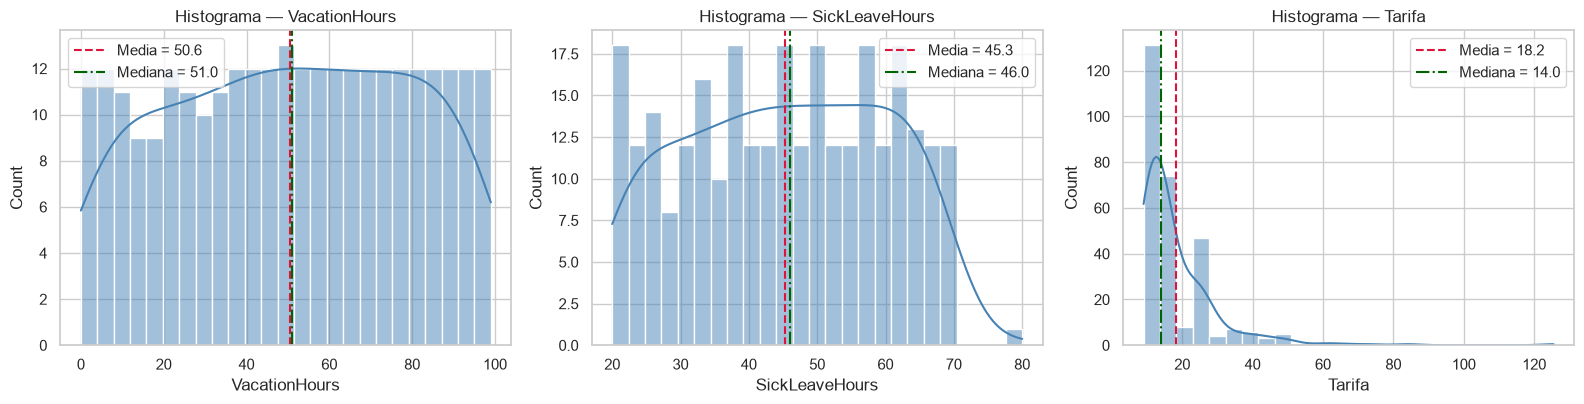

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, col in zip(axes, num_cols):
    sns.histplot(dataset[col], bins=25, kde=True, ax=ax, color="steelblue")
    ax.axvline(dataset[col].mean(), color="crimson", ls="--", label=f"Media = {dataset[col].mean():.1f}")
    ax.axvline(dataset[col].median(), color="darkgreen", ls="-.", label=f"Mediana = {dataset[col].median():.1f}")
    ax.set_title(f"Histograma — {col}")
    ax.legend()
plt.tight_layout()
plt.show()


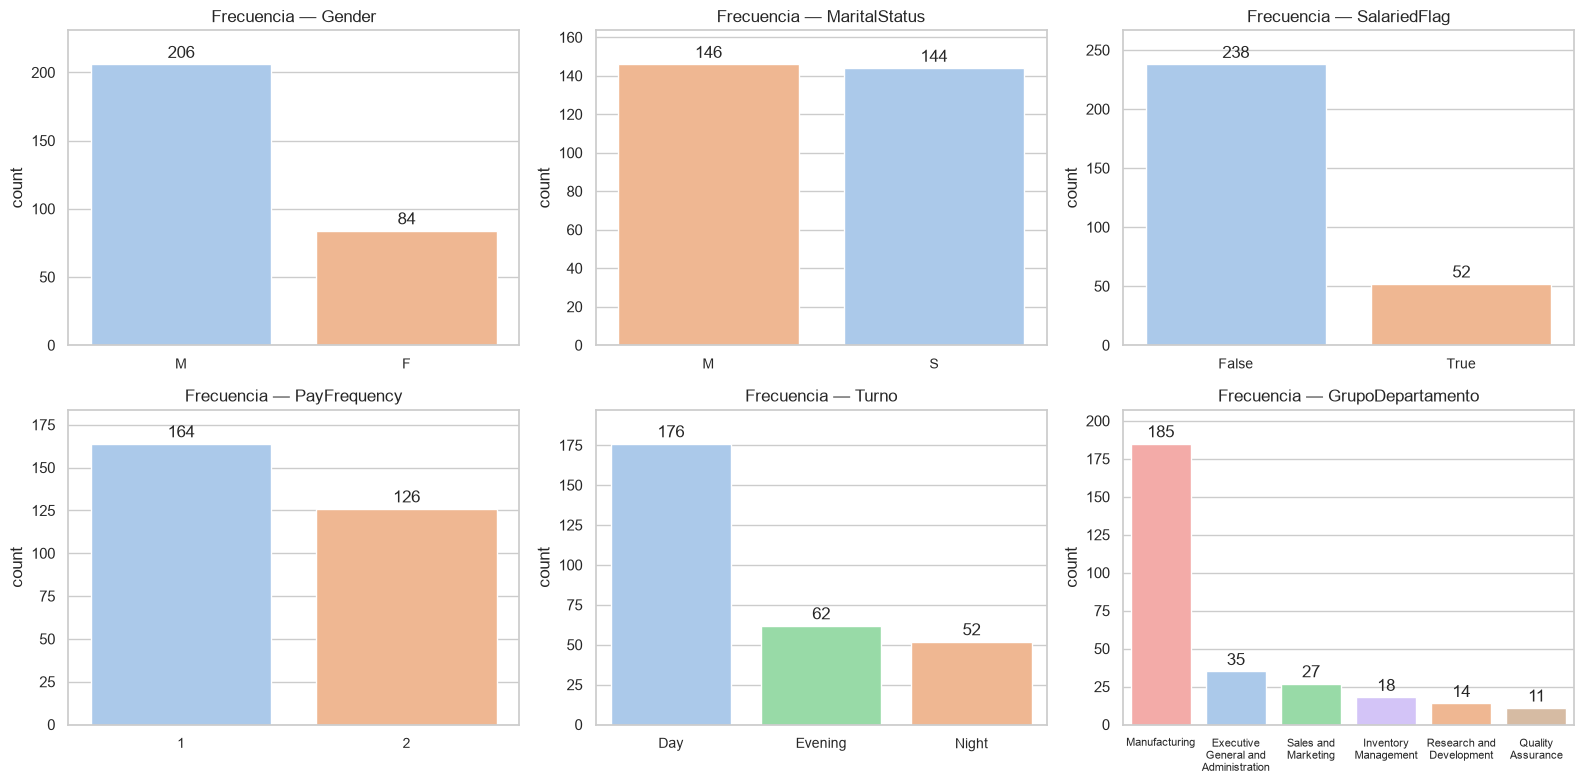

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), cat_bajas):
    orden = dataset[col].value_counts().index
    sns.countplot(data=dataset, x=col, order=orden, hue=col, legend=False, palette="pastel", ax=ax)
    for cont in ax.containers:
        ax.bar_label(cont, padding=2)
    ax.set_title(f"Frecuencia — {col}")
    ax.set_xlabel("")
    ax.margins(y=0.12)
    ax.set_xticks(ax.get_xticks())
    ax.set_xticklabels([textwrap.fill(t.get_text(), 14) for t in ax.get_xticklabels()], fontsize=8 if col == "GrupoDepartamento" else 10)
plt.tight_layout()
plt.show()


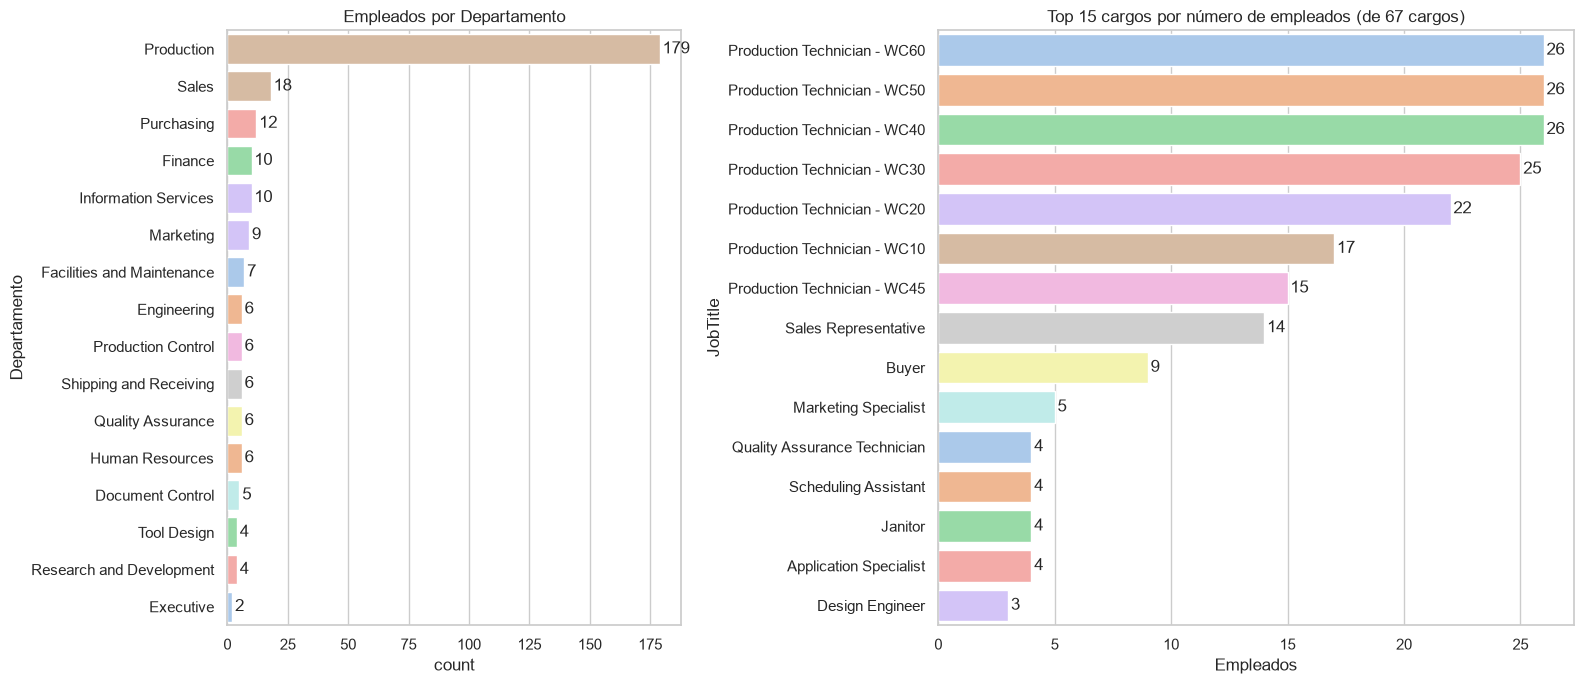

Frecuencias relativas (%):


Turno,Day,Evening,Night
Turno,,,
%,60.70,21.40,17.90


GrupoDepartamento,Manufacturing,Executive General and Administration,Sales and Marketing,Inventory Management,Research and Development,Quality Assurance
GrupoDepartamento,,,,,,
%,63.80,12.10,9.30,6.20,4.80,3.80


Gender,M,F
Gender,,
%,71.00,29.00


MaritalStatus,M,S
MaritalStatus,,
%,50.30,49.70


SalariedFlag,False,True
SalariedFlag,,
%,82.10,17.90


PayFrequency,1,2
PayFrequency,,
%,56.60,43.40


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={"width_ratios": [1, 1.4]})

orden_dep = dataset["Departamento"].value_counts().index
sns.countplot(data=dataset, y="Departamento", order=orden_dep, hue="Departamento", legend=False, palette="pastel", ax=axes[0])
axes[0].set_title("Empleados por Departamento")

top_jobs = dataset["JobTitle"].value_counts().head(15)
sns.barplot(x=top_jobs.values, y=top_jobs.index, hue=top_jobs.index, legend=False, palette="pastel", ax=axes[1])
axes[1].set_title(f"Top 15 cargos por número de empleados (de {dataset['JobTitle'].nunique()} cargos)")
axes[1].set_xlabel("Empleados")
for ax in axes:
    for cont in ax.containers:
        ax.bar_label(cont, padding=2)
plt.tight_layout()
plt.show()

print("Frecuencias relativas (%):")
for col in ["Turno", "GrupoDepartamento", "Gender", "MaritalStatus", "SalariedFlag", "PayFrequency"]:
    display((dataset[col].value_counts(normalize=True) * 100).round(1).to_frame("%").T.rename_axis(col))


## 2.B Medidas de tendencia central (media, mediana, moda)


In [11]:
def moda(s):
    m = s.mode()
    return m.iloc[0] if not m.empty else np.nan

tendencia = pd.DataFrame({
    "Media": dataset[num_cols].mean(),
    "Mediana": dataset[num_cols].median(),
    "Moda": dataset[num_cols].apply(moda),
    "Media − Mediana": dataset[num_cols].mean() - dataset[num_cols].median(),
    "Asimetría (skew)": dataset[num_cols].skew(),
})
display(tendencia)

print("Moda de las variables categóricas:")
modas_cat = pd.DataFrame({
    "Moda": [dataset[c].mode().iloc[0] for c in cat_bajas + cat_altas],
    "Frecuencia": [int(dataset[c].value_counts().iloc[0]) for c in cat_bajas + cat_altas],
    "% del total": [dataset[c].value_counts(normalize=True).iloc[0] * 100 for c in cat_bajas + cat_altas],
}, index=cat_bajas + cat_altas)
display(modas_cat)


,Media,Mediana,Moda,Media − Mediana,Asimetría (skew)
VacationHours,50.61,51.00,48.00,-0.39,-0.07
SickLeaveHours,45.31,46.00,64.00,-0.69,-0.06
Tarifa,18.19,14.00,9.50,4.19,3.92


Moda de las variables categóricas:


,Moda,Frecuencia,% del total
Gender,M,206,71.03
MaritalStatus,M,146,50.34
SalariedFlag,False,238,82.07
PayFrequency,1,164,56.55
Turno,Day,176,60.69
GrupoDepartamento,Manufacturing,185,63.79
Departamento,Production,179,61.72
JobTitle,Production Technician - WC40,26,8.97


## 2.C Medidas separatrices y outliers (método IQR)


In [12]:
percentiles = [0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95]
separatrices = dataset[num_cols].quantile(percentiles).T
separatrices.columns = ["P5", "P10 (D1)", "Q1 (P25)", "Q2 (Mediana)", "Q3 (P75)", "P90 (D9)", "P95"]
display(separatrices)


,P5,P10 (D1),Q1 (P25),Q2 (Mediana),Q3 (P75),P90 (D9),P95
VacationHours,4.45,9.00,26.25,51.00,75.00,90.00,94.55
SickLeaveHours,22.00,24.00,33.00,46.00,58.00,65.00,67.00
Tarifa,9.50,9.50,11.00,14.00,23.08,28.85,40.32


,Q1,Q3,IQR,Límite inferior,Límite superior,Outliers,% outliers
Variable,,,,,,,
VacationHours,26.25,75.00,48.75,-46.88,148.12,0,0.00
SickLeaveHours,33.00,58.00,25.00,-4.50,95.50,0,0.00
Tarifa,11.00,23.08,12.08,-7.12,41.19,13,4.48


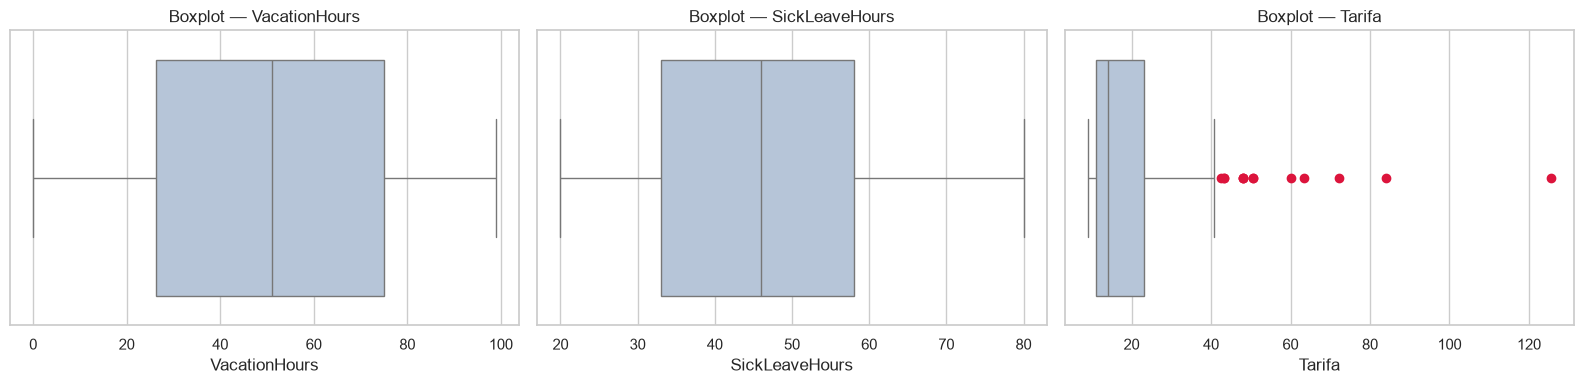

In [13]:
resumen_iqr = []
mascaras = {}
for col in num_cols:
    q1, q3 = dataset[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mascara = (dataset[col] < lim_inf) | (dataset[col] > lim_sup)
    mascaras[col] = mascara
    resumen_iqr.append({"Variable": col, "Q1": q1, "Q3": q3, "IQR": iqr,
                        "Límite inferior": lim_inf, "Límite superior": lim_sup,
                        "Outliers": int(mascara.sum()), "% outliers": mascara.mean() * 100})
resumen_iqr = pd.DataFrame(resumen_iqr).set_index("Variable")
display(resumen_iqr)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(x=dataset[col], ax=ax, color="lightsteelblue", flierprops={"markerfacecolor": "crimson", "markeredgecolor": "crimson"})
    ax.set_title(f"Boxplot — {col}")
plt.tight_layout()
plt.show()


In [14]:
# ¿Quiénes son los outliers de Tarifa?
out_tarifa = (dataset.loc[mascaras["Tarifa"], ["BusinessEntityID", "JobTitle", "Departamento", "Turno", "Tarifa"]]
              .sort_values("Tarifa", ascending=False))
print(f"Outliers de Tarifa: {len(out_tarifa)} empleados")
display(out_tarifa)


Outliers de Tarifa: 13 empleados


,BusinessEntityID,JobTitle,Departamento,Turno,Tarifa
0,1,Chief Executive Officer,Executive,Day,125.50
24,25,Vice President of Production,Production,Day,84.13
272,273,Vice President of Sales,Sales,Day,72.12
1,2,Vice President of Engineering,Engineering,Day,63.46
233,234,Chief Financial Officer,Executive,Day,60.10
6,7,Research and Development Manager,Research and Development,Day,50.48
262,263,Information Services Manager,Information Services,Day,50.48
284,285,Pacific Sales Manager,Sales,Day,48.10
273,274,North American Sales Manager,Sales,Day,48.10
286,287,European Sales Manager,Sales,Day,48.10


## 2.D Medidas de dispersión (rango, varianza, desviación estándar, CV)


In [15]:
dispersion = pd.DataFrame({
    "Mínimo": dataset[num_cols].min(),
    "Máximo": dataset[num_cols].max(),
    "Rango": dataset[num_cols].max() - dataset[num_cols].min(),
    "Varianza": dataset[num_cols].var(),
    "Desv. estándar": dataset[num_cols].std(),
    "CV (%)": dataset[num_cols].std() / dataset[num_cols].mean() * 100,
    "IQR": dataset[num_cols].quantile(0.75) - dataset[num_cols].quantile(0.25),
})
display(dispersion)


,Mínimo,Máximo,Rango,Varianza,Desv. estándar,CV (%),IQR
VacationHours,0.00,99.00,99.00,828.65,28.79,56.87,48.75
SickLeaveHours,20.00,80.00,60.00,211.42,14.54,32.09,25.00
Tarifa,9.00,125.50,116.50,151.06,12.29,67.57,12.08


## Conclusiones 2: Análisis descriptivo

**Variables categóricas (2.A)**
- Producción concentra **179 de 290 empleados (61.7 %)**; el grupo *Manufacturing* llega al 63.8 %. Hay 16 departamentos pero 14 tienen 12 empleados o menos.
- `JobTitle` es muy atomizado: 67 cargos, 28 con un solo empleado. Los más frecuentes son los *Production Technician* (WC30–WC60, 22–26 empleados cada uno).
- El turno **Day** reúne al 60.7 % de la plantilla (Evening 21.4 %, Night 17.9 %). El 71 % son hombres, el estado civil está equilibrado (50.3 % casados) y solo el 17.9 % tiene salario fijo (`SalariedFlag`).

**Tendencia central (2.B)**
- `VacationHours` (media 50.6, mediana 51) y `SickLeaveHours` (media 45.3, mediana 46) son **simétricas** (asimetría ≈ −0.07): media y mediana casi coinciden y el histograma es plano/amplio, sin un valor dominante.
- `Tarifa` es **fuertemente asimétrica a la derecha** (asimetría 3.92): media 18.19 > mediana 14.00 > moda 9.50. La media está inflada por pocos cargos directivos, así que **la mediana representa mejor al empleado típico**.

**Separatrices y outliers IQR (2.C)**
- `Tarifa`: Q1 = 11.00, Q3 = 23.08, IQR = 12.08, límite superior = 41.19. Hay **13 outliers (4.5 %)**, todos por arriba y todos del turno Day: directivos y gerentes (CEO 125.50, VP de Producción 84.13, VP de Ventas 72.12, etc.).
- `VacationHours` y `SickLeaveHours`: **0 outliers**. Los valores extremos de `Tarifa` son legítimos (roles ejecutivos), por lo que **no deben eliminarse**; conviene usar mediana o análisis separado por nivel jerárquico.

**Dispersión (2.D)**
- Desviación estándar: `VacationHours` 28.8 (varianza 828.7), `SickLeaveHours` 14.5 (211.4), `Tarifa` 12.3 (151.1).
- En términos relativos (CV), `Tarifa` es la más dispersa (**67.6 %**), seguida de `VacationHours` (56.9 %) y `SickLeaveHours` (32.1 %). Aunque la varianza de vacaciones es mayor en valor absoluto, esto se debe a la escala (0–99 horas), no a una mayor heterogeneidad que la tarifa.

**Conclusión:** la plantilla es mayoritariamente operativa, diurna y de producción. Las horas de ausencia se comportan de forma regular, mientras que la compensación está muy sesgada y condicionada por unos pocos cargos de alta dirección.


# 3. Análisis por segmentos

La variable de interés es `Tarifa` (pago por hora), acompañada de `VacationHours` y `SickLeaveHours`. Como `JobTitle` tiene muchos valores y varios segmentos son muy pequeños, **cada tabla incluye el número de empleados (`n`)**: un promedio con n = 1 o 2 no es concluyente.


In [16]:
def resumen_segmento(col, minimo_n=1):
    g = dataset.groupby(col).agg(
        n=("BusinessEntityID", "count"),
        Tarifa_media=("Tarifa", "mean"),
        Tarifa_mediana=("Tarifa", "median"),
        Tarifa_std=("Tarifa", "std"),
        Tarifa_min=("Tarifa", "min"),
        Tarifa_max=("Tarifa", "max"),
        Vacaciones_media=("VacationHours", "mean"),
        Enfermedad_media=("SickLeaveHours", "mean"),
    )
    g["% del total"] = g["n"] / g["n"].sum() * 100
    return g[g["n"] >= minimo_n].sort_values("Tarifa_media", ascending=False)

def boxplot_segmento(col, orden, titulo, alto=6):
    plt.figure(figsize=(11, alto))
    sns.boxplot(data=dataset, y=col, x="Tarifa", order=orden, hue=col, legend=False, palette="pastel", orient="h")
    plt.title(titulo)
    plt.xlabel("Tarifa (por hora)")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()


## 3.A Segmentación por cargo (`JobTitle`)


In [17]:
seg_job = resumen_segmento("JobTitle")
print(f"{len(seg_job)} cargos distintos | {int((seg_job['n'] == 1).sum())} cargos con un solo empleado\n")

print("Top 10 cargos con mayor tarifa media:")
display(seg_job.head(10))
print("Top 10 cargos con menor tarifa media:")
display(seg_job.tail(10))
print("Top 10 cargos con más empleados:")
display(seg_job.sort_values("n", ascending=False).head(10))


67 cargos distintos | 28 cargos con un solo empleado

Top 10 cargos con mayor tarifa media:


,n,Tarifa_media,Tarifa_mediana,Tarifa_std,Tarifa_min,Tarifa_max,Vacaciones_media,Enfermedad_media,% del total
JobTitle,,,,,,,,,
Chief Executive Officer,1,125.50,125.50,NaN,125.50,125.50,99.00,69.00,0.34
Vice President of Production,1,84.13,84.13,NaN,84.13,84.13,64.00,52.00,0.34
Vice President of Sales,1,72.12,72.12,NaN,72.12,72.12,10.00,25.00,0.34
Vice President of Engineering,1,63.46,63.46,NaN,63.46,63.46,1.00,20.00,0.34
Chief Financial Officer,1,60.10,60.10,NaN,60.10,60.10,0.00,20.00,0.34
Information Services Manager,1,50.48,50.48,NaN,50.48,50.48,65.00,52.00,0.34
Pacific Sales Manager,1,48.10,48.10,NaN,48.10,48.10,20.00,30.00,0.34
North American Sales Manager,1,48.10,48.10,NaN,48.10,48.10,14.00,27.00,0.34
European Sales Manager,1,48.10,48.10,NaN,48.10,48.10,21.00,30.00,0.34


Top 10 cargos con menor tarifa media:


,n,Tarifa_media,Tarifa_mediana,Tarifa_std,Tarifa_min,Tarifa_max,Vacaciones_media,Enfermedad_media,% del total
JobTitle,,,,,,,,,
Production Technician - WC60,26,12.45,12.45,0.00,12.45,12.45,26.50,33.00,8.97
Production Technician - WC50,26,11.00,11.00,0.00,11.00,11.00,46.65,43.08,8.97
Quality Assurance Technician,4,10.58,10.58,0.00,10.58,10.58,83.50,61.50,1.38
Document Control Assistant,2,10.25,10.25,0.00,10.25,10.25,78.50,59.00,0.69
Production Technician - WC45,15,10.00,10.00,0.00,10.00,10.00,80.00,59.73,5.17
Facilities Administrative Assistant,1,9.75,9.75,NaN,9.75,9.75,87.00,63.00,0.34
Shipping and Receiving Clerk,2,9.50,9.50,0.00,9.50,9.50,94.50,67.00,0.69
Production Technician - WC30,25,9.50,9.50,0.00,9.50,9.50,34.00,36.76,8.62
Janitor,4,9.25,9.25,0.00,9.25,9.25,89.50,64.50,1.38


Top 10 cargos con más empleados:


,n,Tarifa_media,Tarifa_mediana,Tarifa_std,Tarifa_min,Tarifa_max,Vacaciones_media,Enfermedad_media,% del total
JobTitle,,,,,,,,,
Production Technician - WC40,26,15.00,15.00,0.00,15.00,15.00,59.50,49.50,8.97
Production Technician - WC50,26,11.00,11.00,0.00,11.00,11.00,46.65,43.08,8.97
Production Technician - WC60,26,12.45,12.45,0.00,12.45,12.45,26.50,33.00,8.97
Production Technician - WC30,25,9.50,9.50,0.00,9.50,9.50,34.00,36.76,8.62
Production Technician - WC20,22,14.00,14.00,0.00,14.00,14.00,10.50,25.00,7.59
Production Technician - WC10,17,13.45,13.45,0.00,13.45,13.45,91.00,65.24,5.86
Production Technician - WC45,15,10.00,10.00,0.00,10.00,10.00,80.00,59.73,5.17
Sales Representative,14,23.08,23.08,0.00,23.08,23.08,31.00,35.21,4.83
Buyer,9,18.27,18.27,0.00,18.27,18.27,56.00,47.78,3.10


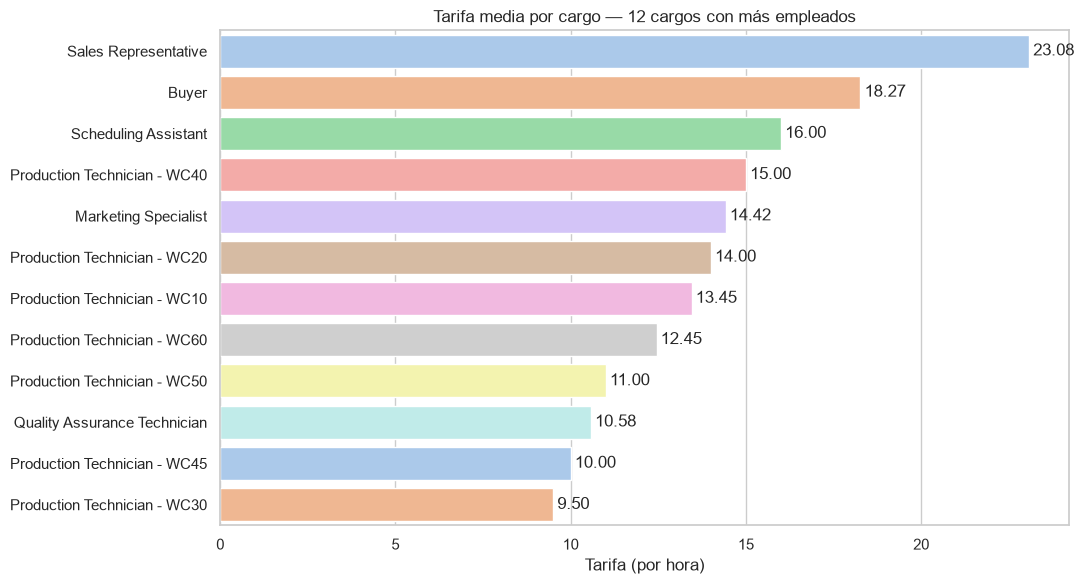

Cargos con 2+ empleados: 39 | con tarifa idéntica para todos (std = 0): 37


In [18]:
# Los cargos más numerosos tienen tarifa casi constante (std = 0), por lo que un boxplot sería una línea: se usa barras
top12 = dataset["JobTitle"].value_counts().head(12).index
datos = (dataset[dataset["JobTitle"].isin(top12)].groupby("JobTitle")["Tarifa"].agg(["mean", "count"])
         .sort_values("mean", ascending=False))
plt.figure(figsize=(11, 6))
ax = sns.barplot(x=datos["mean"], y=datos.index, hue=datos.index, legend=False, palette="pastel")
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.2f", padding=3)
plt.title("Tarifa media por cargo — 12 cargos con más empleados")
plt.xlabel("Tarifa (por hora)"); plt.ylabel("")
plt.tight_layout(); plt.show()

# ¿La tarifa depende del cargo? Variabilidad de Tarifa dentro de cada cargo con 2+ empleados
multi = dataset.groupby("JobTitle")["Tarifa"].agg(n="count", std="std").query("n >= 2")
print(f"Cargos con 2+ empleados: {len(multi)} | con tarifa idéntica para todos (std = 0): {int((multi['std'] == 0).sum())}")


### Cargos con más horas de vacaciones

Complemento a la segmentación por cargo. Se incluye `n` porque un promedio con uno o dos empleados no es concluyente.


In [19]:
print("Top 10 cargos con más horas de vacaciones promedio (con n):")
display(seg_job.sort_values("Vacaciones_media", ascending=False)[["n", "Vacaciones_media"]].head(10))


Top 10 cargos con más horas de vacaciones promedio (con n):


,n,Vacaciones_media
JobTitle,,
Chief Executive Officer,1,99.00
Stocker,3,97.00
Shipping and Receiving Clerk,2,94.50
Shipping and Receiving Supervisor,1,93.00
Maintenance Supervisor,1,92.00
Production Technician - WC10,17,91.00
Janitor,4,89.50
Facilities Administrative Assistant,1,87.00
Facilities Manager,1,86.00


## 3.B Segmentación por departamento (`Departamento`)


,n,Tarifa_media,Tarifa_mediana,Tarifa_std,Tarifa_min,Tarifa_max,Vacaciones_media,Enfermedad_media,% del total
Departamento,,,,,,,,,
Executive,2,92.80,92.80,46.25,60.10,125.50,49.50,44.50,0.69
Research and Development,4,43.67,41.67,4.60,40.87,50.48,50.50,54.00,1.38
Engineering,6,40.14,34.38,12.14,32.69,63.46,3.50,21.50,2.07
Information Services,10,34.16,32.45,7.62,27.40,50.48,69.50,54.50,3.45
Sales,18,29.97,23.08,14.20,23.08,72.12,27.72,33.61,6.21
Tool Design,4,27.17,26.92,2.54,25.00,29.85,18.00,37.75,1.38
Finance,10,23.94,19.00,9.03,13.46,43.27,59.50,49.50,3.45
Production Control,6,18.68,16.00,4.16,16.00,24.52,45.50,42.50,2.07
Purchasing,12,18.33,18.27,4.25,12.75,30.00,54.50,47.00,4.14


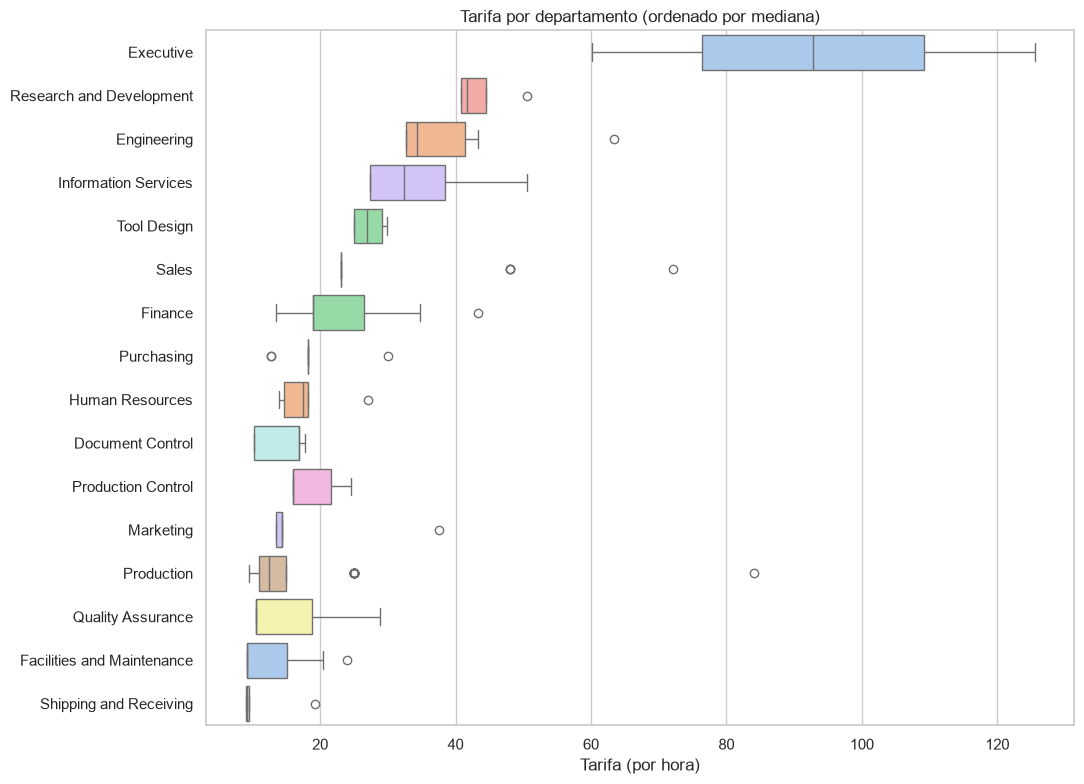

In [20]:
seg_dep = resumen_segmento("Departamento")
display(seg_dep)
boxplot_segmento("Departamento", seg_dep.sort_values("Tarifa_mediana", ascending=False).index,
                 "Tarifa por departamento (ordenado por mediana)", alto=8)


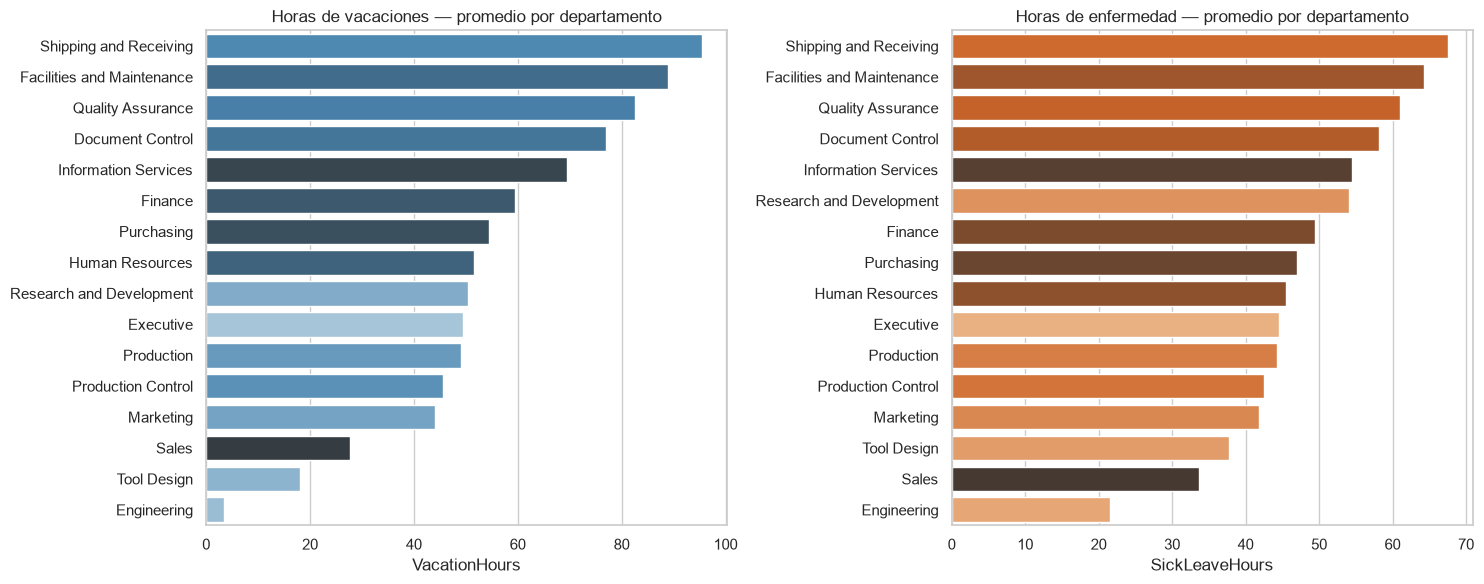

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
orden_dep = seg_dep.sort_values("Vacaciones_media", ascending=False).index
sns.barplot(data=dataset, y="Departamento", x="VacationHours", order=orden_dep, hue="Departamento", legend=False,
            palette="Blues_d", errorbar=None, ax=axes[0])
axes[0].set_title("Horas de vacaciones — promedio por departamento")
orden_enf = seg_dep.sort_values("Enfermedad_media", ascending=False).index
sns.barplot(data=dataset, y="Departamento", x="SickLeaveHours", order=orden_enf, hue="Departamento", legend=False,
            palette="Oranges_d", errorbar=None, ax=axes[1])
axes[1].set_title("Horas de enfermedad — promedio por departamento")
for ax in axes: ax.set_ylabel("")
plt.tight_layout(); plt.show()


## 3.C Segmentación por turno (`Turno`)


,n,Tarifa_media,Tarifa_mediana,Tarifa_std,Tarifa_min,Tarifa_max,Vacaciones_media,Enfermedad_media,% del total
Turno,,,,,,,,,
Day,176,20.94,15.00,14.63,9.00,125.50,49.26,44.79,60.69
Evening,62,14.00,12.45,5.13,9.00,32.45,49.47,44.48,21.38
Night,52,13.86,12.45,4.89,9.00,25.00,56.58,48.04,17.93


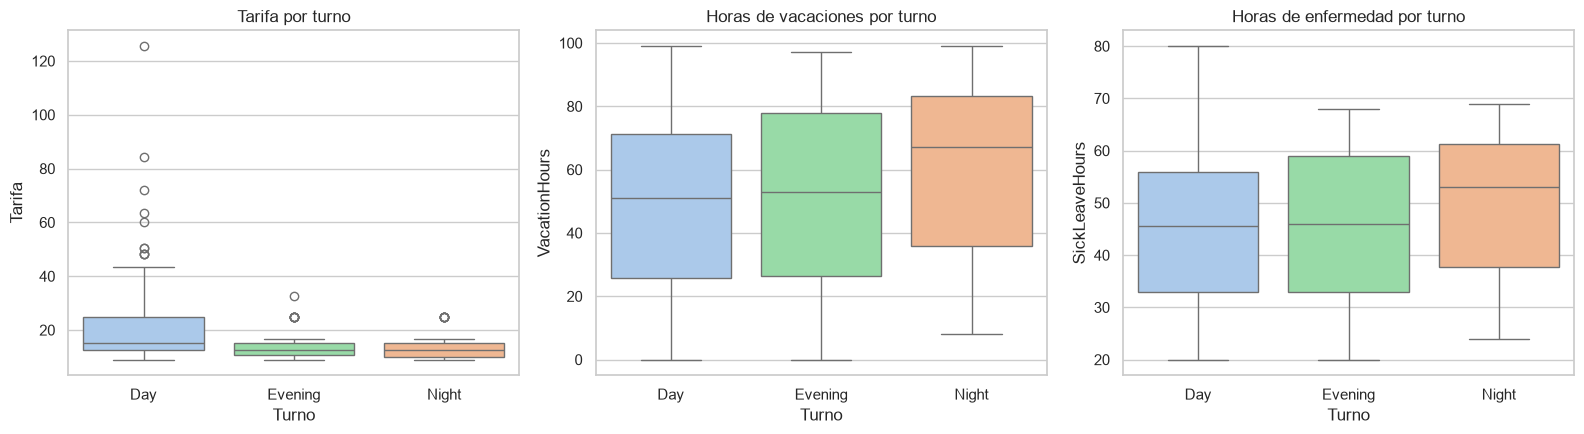

In [22]:
seg_turno = resumen_segmento("Turno")
display(seg_turno)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
orden_t = ["Day", "Evening", "Night"]
sns.boxplot(data=dataset, x="Turno", y="Tarifa", order=orden_t, hue="Turno", legend=False, palette="pastel", ax=axes[0])
axes[0].set_title("Tarifa por turno")
sns.boxplot(data=dataset, x="Turno", y="VacationHours", order=orden_t, hue="Turno", legend=False, palette="pastel", ax=axes[1])
axes[1].set_title("Horas de vacaciones por turno")
sns.boxplot(data=dataset, x="Turno", y="SickLeaveHours", order=orden_t, hue="Turno", legend=False, palette="pastel", ax=axes[2])
axes[2].set_title("Horas de enfermedad por turno")
plt.tight_layout(); plt.show()


In [23]:
# El turno diurno incluye los cargos administrativos mejor pagados: se compara también solo el departamento de Producción
prod = dataset[dataset["Departamento"] == "Production"]
print("Tarifa por turno — solo departamento de Producción:")
display(prod.groupby("Turno")["Tarifa"].agg(n="count", media="mean", mediana="median", std="std"))


Tarifa por turno — solo departamento de Producción:


,n,media,mediana,std
Turno,,,,
Day,79,14.28,12.45,8.95
Evening,54,13.98,12.95,4.66
Night,46,14.13,12.95,5.00


## 3.D Cruce `Departamento × Turno` y síntesis de segmentos


Turno,Day,Evening,Night,Total
Departamento,,,,
Document Control,3,1,1,5
Engineering,6,0,0,6
Executive,2,0,0,2
Facilities and Maintenance,3,2,2,7
Finance,10,0,0,10
Human Resources,6,0,0,6
Information Services,9,1,0,10
Marketing,9,0,0,9
Production,79,54,46,179


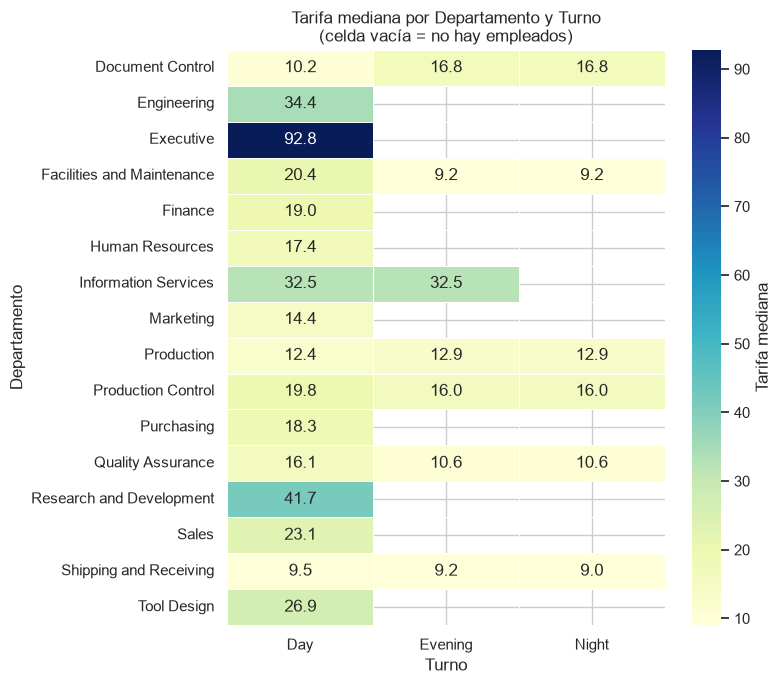

In [24]:
frecuencias = pd.crosstab(dataset["Departamento"], dataset["Turno"], margins=True, margins_name="Total")
display(frecuencias)

tabla_tarifa = dataset.pivot_table(index="Departamento", columns="Turno", values="Tarifa", aggfunc="median")
plt.figure(figsize=(8, 7))
sns.heatmap(tabla_tarifa, annot=True, fmt=".1f", cmap="YlGnBu", linewidths=0.5, cbar_kws={"label": "Tarifa mediana"})
plt.title("Tarifa mediana por Departamento y Turno\n(celda vacía = no hay empleados)")
plt.tight_layout(); plt.show()


In [25]:
# Segmentación por rol: asalariados vs. por hora y por género dentro de la tarifa
display(dataset.groupby("SalariedFlag")["Tarifa"].agg(n="count", media="mean", mediana="median"))
display(dataset.groupby("Gender")["Tarifa"].agg(n="count", media="mean", mediana="median"))


,n,media,mediana
SalariedFlag,,,
False,238,14.32,13.45
True,52,35.88,28.12


,n,media,mediana
Gender,,,
F,84,19.23,14.00
M,206,17.76,14.00


## 3.E Contrataciones por año

Evolución del número de empleados según el año de su fecha de contratación (`HireDate`).


,Anio,Contrataciones
0,2006,1
1,2007,6
2,2008,74
3,2009,148
4,2010,38
5,2011,16
6,2012,4
7,2013,3


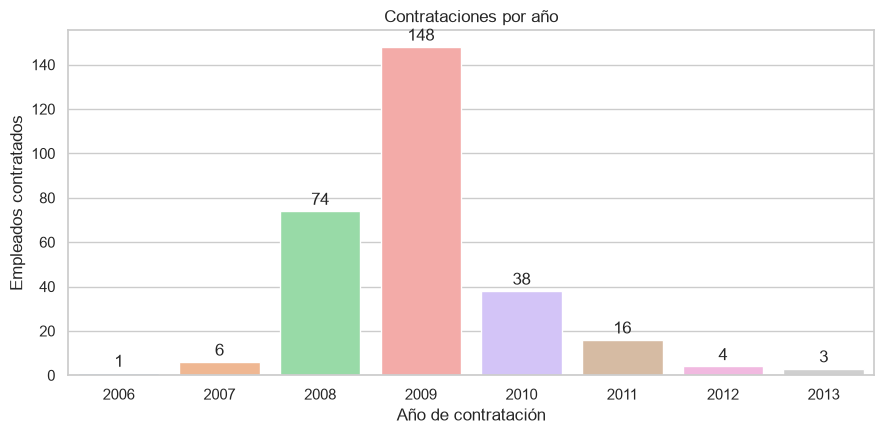

In [26]:
contrataciones = (
    dataset["HireDate"].dt.year.value_counts()
    .sort_index()
    .rename_axis("Anio")
    .reset_index(name="Contrataciones")
)
display(contrataciones)

plt.figure(figsize=(9, 4.5))
ax = sns.barplot(data=contrataciones, x="Anio", y="Contrataciones", hue="Anio", legend=False, palette="pastel")
for cont in ax.containers:
    ax.bar_label(cont, padding=2)
plt.title("Contrataciones por año")
plt.xlabel("Año de contratación")
plt.ylabel("Empleados contratados")
plt.tight_layout()
plt.show()


El pico máximo de contratación se registra en 2009 y la mayor parte del crecimiento de la plantilla ocurre entre 2008 y 2010. Esto sugiere una etapa de expansión fuerte de personal seguida de una desaceleración progresiva.


## Conclusiones 3: Análisis por segmentos

**Por cargo (3.A)**
- La `Tarifa` está determinada casi por completo por el cargo: de los 39 cargos con 2 o más empleados, **37 tienen exactamente la misma tarifa para todos** (std = 0). Por eso los boxplots por cargo serían degenerados y se usaron barras.
- Los cargos mejor pagados son de dirección (CEO 125.50, VP de Producción 84.13, VP de Ventas 72.12) y todos tienen n = 1: son casos individuales, no un patrón estadístico. Los menos pagados son operativos (*Stocker* 9.00, *Janitor* 9.25, *Production Technician WC30* 9.50).
- Entre los técnicos de producción hay diferencias entre estaciones de trabajo (WC30 = 9.50 vs. WC40 = 15.00) con un n comparable (≈ 25), lo que sugiere una escala salarial por estación.

**Por departamento (3.B)**
- Mayor tarifa media: Executive (92.80, n = 2), Research and Development (43.67, n = 4), Engineering (40.14, n = 6) e Information Services (34.16, n = 10). Los más bajos: Shipping and Receiving (10.87), Facilities and Maintenance (13.03) y **Production (14.15, n = 179)**.
- Dentro de varios departamentos la media supera a la mediana (Sales: 29.97 vs 23.08), señal de que unos pocos gerentes elevan el promedio.
- El departamento de Engineering destaca por tener muy pocas horas de vacaciones acumuladas (≈ 3.5 en promedio), un punto a revisar desde RR. HH.

**Por turno (3.C)**
- Day tiene tarifa media de 20.94 frente a 14.00 (Evening) y 13.86 (Night). Sin embargo, la **mediana** es 15.00 vs 12.45 y 12.45, y la diferencia se explica por composición: todos los cargos administrativos y directivos trabajan en turno Day.
- Comparando **solo Producción**, los turnos son equivalentes (medias 14.28, 13.98 y 14.13). **No hay evidencia de pago diferencial por turno nocturno o vespertino.**
- Night muestra algo más de horas de vacaciones (56.6) y de enfermedad (48.0) que Day (49.3 y 44.8); es una diferencia leve que conviene validar con más datos.

**Cruce y otros segmentos (3.D)**
- Solo 6 de los 16 departamentos tienen presencia en los tres turnos; los turnos Evening y Night están dominados por Producción (54 y 46 de 62 y 52 empleados). Los demás departamentos operan casi exclusivamente en turno Day.
- Los empleados con **salario fijo** ganan en promedio 35.88 frente a 14.32 de los pagados por hora. Por género, la media es 19.23 (F) vs 17.76 (M), pero la **mediana es idéntica (14.00)**: la diferencia de media se debe a pocos cargos y no a un patrón general.

**Conclusión:** la compensación depende del cargo y del nivel jerárquico, no del turno. Los análisis comparativos deben controlar por departamento/cargo y considerar el tamaño de cada segmento (muchos tienen n < 10).


# 4. Matriz de correlación y selección de variables


## 4.0 Preparación: edad y antigüedad

Se crea `datos_modelado`, una copia del dataset con dos variables derivadas: `EdadAnios` y `AntiguedadAnios`. Ambas se calculan respecto a la fecha de contratación más reciente del dataset (no respecto al día de hoy), para que los resultados sean reproducibles.


In [27]:
fecha_referencia = dataset["HireDate"].max()
print(f"Fecha de referencia: {fecha_referencia.date()}")

datos_modelado = dataset.copy()
datos_modelado["EdadAnios"] = (fecha_referencia - datos_modelado["BirthDate"]).dt.days / 365.25
datos_modelado["AntiguedadAnios"] = (fecha_referencia - datos_modelado["HireDate"]).dt.days / 365.25

display(datos_modelado[["EdadAnios", "AntiguedadAnios"]].describe().round(2))


Fecha de referencia: 2013-05-30


,EdadAnios,AntiguedadAnios
count,290.00,290.00
mean,34.90,4.03
std,9.24,0.92
min,22.00,0.00
25%,27.01,3.64
50%,34.61,4.32
75%,39.69,4.42
max,61.62,6.92


## 4.1 Selección de variables numéricas

Para la matriz se incluyen variables cuantitativas que pueden aportar información sobre el perfil laboral: tarifa de pago, horas de vacaciones, horas de licencia por enfermedad, antigüedad y edad. Se excluyen `BusinessEntityID` por ser un identificador y `PayFrequency` porque sus códigos representan categorías, no una magnitud continua.


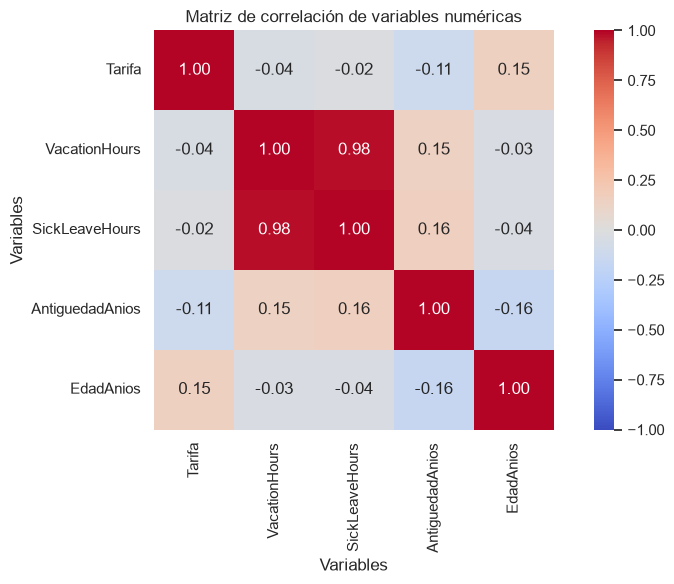

Interpretación: los valores cercanos a 1 indican asociación lineal positiva; los cercanos a -1, asociación negativa; y los cercanos a 0, poca asociación lineal.


In [28]:
variables_correlacion = [
    "Tarifa",
    "VacationHours",
    "SickLeaveHours",
    "AntiguedadAnios",
    "EdadAnios",
]

matriz_correlacion = datos_modelado[variables_correlacion].corr(numeric_only=True)

plt.figure(figsize=(9, 6))
sns.heatmap(
    matriz_correlacion,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True
)
plt.title("Matriz de correlación de variables numéricas")
plt.xlabel("Variables")
plt.ylabel("Variables")
plt.tight_layout()
plt.show()

print("Interpretación: los valores cercanos a 1 indican asociación lineal positiva; "
      "los cercanos a -1, asociación negativa; y los cercanos a 0, poca asociación lineal.")


In [29]:
# Pares de variables con mayor correlación absoluta (sin duplicar pares)
correlaciones_pares = (
    matriz_correlacion.where(
        np.triu(np.ones(matriz_correlacion.shape), k=1).astype(bool)
    )
    .stack()
    .rename("Correlacion")
    .reset_index()
)
correlaciones_pares.columns = ["Variable 1", "Variable 2", "Correlacion"]
correlaciones_pares["Correlacion absoluta"] = correlaciones_pares["Correlacion"].abs()
correlaciones_pares = correlaciones_pares.sort_values(
    "Correlacion absoluta", ascending=False
)

display(correlaciones_pares)

if not correlaciones_pares.empty:
    par_mayor = correlaciones_pares.iloc[0]
    print(
        f"La asociación lineal más alta en valor absoluto se observa entre "
        f"{par_mayor['Variable 1']} y {par_mayor['Variable 2']} "
        f"(r = {par_mayor['Correlacion']:.2f}). "
        "La correlación describe asociación y no demuestra causalidad."
    )


,Variable 1,Variable 2,Correlacion,Correlacion absoluta
7,VacationHours,SickLeaveHours,0.98,0.98
19,AntiguedadAnios,EdadAnios,-0.16,0.16
13,SickLeaveHours,AntiguedadAnios,0.16,0.16
4,Tarifa,EdadAnios,0.15,0.15
8,VacationHours,AntiguedadAnios,0.15,0.15
3,Tarifa,AntiguedadAnios,-0.11,0.11
1,Tarifa,VacationHours,-0.04,0.04
14,SickLeaveHours,EdadAnios,-0.04,0.04
9,VacationHours,EdadAnios,-0.03,0.03
2,Tarifa,SickLeaveHours,-0.02,0.02


La asociación lineal más alta en valor absoluto se observa entre VacationHours y SickLeaveHours (r = 0.98). La correlación describe asociación y no demuestra causalidad.


## 4.2 Análisis de edad y antigüedad

Las variables `EdadAnios` y `AntiguedadAnios` se calcularon usando como referencia la fecha de contratación más reciente del dataset. Este análisis revisa su asociación lineal con la tarifa, las horas de vacaciones y las horas de licencia por enfermedad, y compara esos indicadores entre rangos de antigüedad.

Las correlaciones describen asociaciones lineales, no causalidad. Las diferencias entre rangos también deben interpretarse considerando el número de empleados de cada grupo y que la tarifa puede depender del cargo.


In [30]:
# Resumen descriptivo de edad y antigüedad (en años)
resumen_fechas = (
    datos_modelado[["EdadAnios", "AntiguedadAnios"]]
    .agg(["count", "mean", "median", "min", "max"])
    .T
    .rename_axis("Variable")
)
display(resumen_fechas.round(2))

# Correlación de edad y antigüedad con condiciones laborales
variables_laborales = ["Tarifa", "VacationHours", "SickLeaveHours"]
correlaciones_fechas = datos_modelado[
    ["EdadAnios", "AntiguedadAnios"] + variables_laborales
].corr(numeric_only=True).loc[
    ["EdadAnios", "AntiguedadAnios"], variables_laborales
]
display(correlaciones_fechas.round(2))

for variable_fecha, fila in correlaciones_fechas.iterrows():
    for variable_laboral, correlacion in fila.items():
        if pd.isna(correlacion):
            continue
        direccion = "positiva" if correlacion > 0 else "negativa"
        if abs(correlacion) < 0.1:
            descripcion = "casi nula"
        elif abs(correlacion) < 0.4:
            descripcion = f"{direccion} débil"
        elif abs(correlacion) < 0.7:
            descripcion = f"{direccion} moderada"
        else:
            descripcion = f"{direccion} fuerte"
        print(f"{variable_fecha} - {variable_laboral}: r = {correlacion:.2f} ({descripcion}).")

# Comparación de tarifa y horas disponibles por rango de antigüedad
datos_antiguedad = datos_modelado.dropna(subset=["AntiguedadAnios"]).copy()
datos_antiguedad["RangoAntiguedad"] = pd.cut(
    datos_antiguedad["AntiguedadAnios"],
    bins=[0, 2, 5, float("inf")],
    labels=["0-2 años", ">2-5 años", ">5 años"],
    include_lowest=True,
)
resumen_antiguedad = (
    datos_antiguedad.groupby("RangoAntiguedad", observed=True)
    .agg(
        Empleados=("BusinessEntityID", "count"),
        Edad_media=("EdadAnios", "mean"),
        Tarifa_media=("Tarifa", "mean"),
        Tarifa_mediana=("Tarifa", "median"),
        Vacaciones_promedio=("VacationHours", "mean"),
        Licencia_enfermedad_promedio=("SickLeaveHours", "mean"),
    )
)
display(resumen_antiguedad.round(2))


,count,mean,median,min,max
Variable,,,,,
EdadAnios,290.00,34.90,34.61,22.00,61.62
AntiguedadAnios,290.00,4.03,4.32,0.00,6.92


,Tarifa,VacationHours,SickLeaveHours
EdadAnios,0.15,-0.03,-0.04
AntiguedadAnios,-0.11,0.15,0.16


EdadAnios - Tarifa: r = 0.15 (positiva débil).
EdadAnios - VacationHours: r = -0.03 (casi nula).
EdadAnios - SickLeaveHours: r = -0.04 (casi nula).
AntiguedadAnios - Tarifa: r = -0.11 (negativa débil).
AntiguedadAnios - VacationHours: r = 0.15 (positiva débil).
AntiguedadAnios - SickLeaveHours: r = 0.16 (positiva débil).


,Empleados,Edad_media,Tarifa_media,Tarifa_mediana,Vacaciones_promedio,Licencia_enfermedad_promedio
RangoAntiguedad,,,,,,
0-2 años,16,41.57,26.20,23.08,29.69,34.56
>2-5 años,255,33.37,17.19,14.00,51.74,45.76
>5 años,19,49.85,24.79,25.00,53.11,48.21


### Interpretación de los resultados

Con la fecha de referencia **2013-05-30**, la edad media estimada es de **34.90 años** y la antigüedad media de **4.03 años**. Las correlaciones de edad con tarifa, vacaciones y licencias son muy débiles o casi nulas (r = 0.15, -0.03 y -0.04). La antigüedad también presenta asociaciones débiles: r = -0.11 con tarifa, 0.15 con vacaciones y 0.16 con licencia por enfermedad.

Al agrupar por antigüedad, la tarifa media es 26.20 para el grupo de 0-2 años (16 empleados), 17.19 para más de 2 y hasta 5 años (255 empleados), y 24.79 para más de 5 años (19 empleados). Por tanto, no se observa un aumento lineal de la tarifa con la antigüedad. En cambio, los promedios de vacaciones (29.69, 51.74 y 53.11 horas) y licencias (34.56, 45.76 y 48.21 horas) son mayores en los grupos de más antigüedad.

Estos patrones son descriptivos, no prueban que la edad o antigüedad cause cambios salariales o de horas disponibles. Además, los grupos extremos son pequeños y las diferencias de tarifa pueden reflejar los cargos que componen cada grupo; conviene interpretar las medias junto con el tamaño de muestra y la mediana.


## 4.3 Interpretación y decisión de variables

La matriz permite revisar si algunas variables aportan información similar. Para el clustering se priorizan variables relacionadas con condiciones laborales y disponibilidad de tiempo: `Tarifa`, `VacationHours`, `SickLeaveHours` y `AntiguedadAnios`. La edad se conserva para el análisis de correlación, pero no se incorpora al modelo inicial para evitar que características demográficas dominen la segmentación.

Como K-Means utiliza distancias, las variables seleccionadas se estandarizarán en la sección siguiente. De este modo, las diferencias de escala entre la tarifa y las horas no dominarán automáticamente el resultado.


# 5. Clustering con K-Means

K-Means agrupa empleados con valores similares en las variables seleccionadas. Antes de aplicarlo se escalan las variables con `StandardScaler`, porque el algoritmo calcula distancias y las columnas están expresadas en unidades distintas.

Se comparan varios valores de *k* mediante el método del codo y el coeficiente silhouette. Las gráficas sirven como apoyo para elegir el número de grupos; no existe un único valor correcto de forma automática.


## 5.1 Preparación y escalado de variables


In [31]:
variables_cluster = [
    "Tarifa",
    "VacationHours",
    "SickLeaveHours",
    "AntiguedadAnios",
]

# Usar únicamente registros completos para las variables del modelo
datos_cluster = datos_modelado[variables_cluster].replace([np.inf, -np.inf], np.nan)
mascara_validos = datos_cluster.notna().all(axis=1)
datos_cluster = datos_cluster.loc[mascara_validos].copy()

if len(datos_cluster) < 3:
    raise ValueError("No hay suficientes registros completos para ejecutar K-Means.")

escalador = StandardScaler()
X_escalado = escalador.fit_transform(datos_cluster)

print(f"Empleados incluidos en el clustering: {len(datos_cluster)} de {len(dataset)}")
print("Variables utilizadas:", ", ".join(variables_cluster))


Empleados incluidos en el clustering: 290 de 290
Variables utilizadas: Tarifa, VacationHours, SickLeaveHours, AntiguedadAnios


## 5.2 Elección de k: método del codo y silhouette

Se evalúan valores de k entre 2 y 8 (o hasta el máximo permitido por la cantidad de registros). El método del codo muestra la inercia, mientras que silhouette evalúa qué tan separados y compactos quedan los grupos. Se presentan ambas métricas para tomar una decisión razonada.


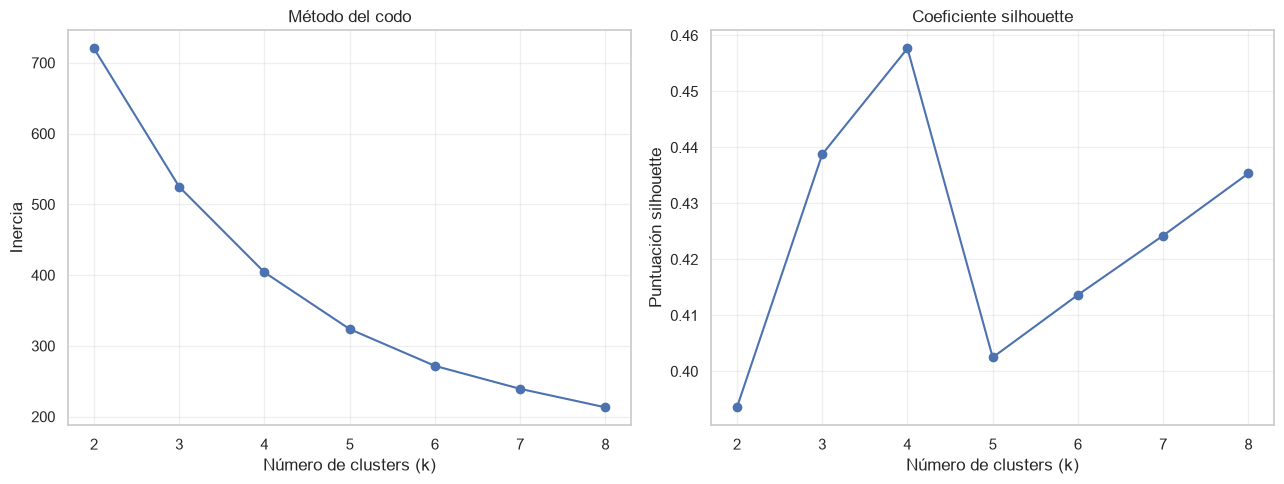

,k,Inercia,Silhouette
0,4,403.93,0.46
1,3,524.77,0.44
2,8,213.16,0.44
3,7,239.27,0.42
4,6,271.74,0.41
5,5,323.70,0.40
6,2,720.37,0.39


El mayor silhouette entre los valores evaluados corresponde a k = 4. Contrasta este resultado con el método del codo antes de definir el número final de grupos.


In [32]:
k_maximo = min(8, len(datos_cluster) - 1)
valores_k = list(range(2, k_maximo + 1))

inercias = []
siluetas = []

for k in valores_k:
    modelo_temporal = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas_temporales = modelo_temporal.fit_predict(X_escalado)
    inercias.append(modelo_temporal.inertia_)
    siluetas.append(silhouette_score(X_escalado, etiquetas_temporales))

fig, ejes = plt.subplots(1, 2, figsize=(13, 5))

ejes[0].plot(valores_k, inercias, marker="o")
ejes[0].set_title("Método del codo")
ejes[0].set_xlabel("Número de clusters (k)")
ejes[0].set_ylabel("Inercia")
ejes[0].set_xticks(valores_k)
ejes[0].grid(True, alpha=0.3)

ejes[1].plot(valores_k, siluetas, marker="o")
ejes[1].set_title("Coeficiente silhouette")
ejes[1].set_xlabel("Número de clusters (k)")
ejes[1].set_ylabel("Puntuación silhouette")
ejes[1].set_xticks(valores_k)
ejes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

tabla_metricas = pd.DataFrame({
    "k": valores_k,
    "Inercia": inercias,
    "Silhouette": siluetas
})
display(tabla_metricas.sort_values("Silhouette", ascending=False).reset_index(drop=True))

k_sugerido_silhouette = valores_k[int(np.argmax(siluetas))]
print(
    f"El mayor silhouette entre los valores evaluados corresponde a k = "
    f"{k_sugerido_silhouette}. Contrasta este resultado con el método del codo "
    "antes de definir el número final de grupos."
)


**Criterio para elegir k:** se revisan conjuntamente la disminución de la inercia y el silhouette. Si el codo sugiere un valor diferente al máximo silhouette, se debe justificar la elección según la claridad y utilidad de los perfiles obtenidos. La siguiente celda permite fijar el k elegido tras revisar las gráficas.


In [33]:
# Ajusta este valor después de revisar las dos gráficas.
# Por defecto se utiliza el k con mayor silhouette; puedes cambiarlo si el codo
# y la interpretación de los perfiles justifican otra cantidad de grupos.
k_final = k_sugerido_silhouette

modelo_kmeans = KMeans(n_clusters=k_final, random_state=42, n_init=10)
etiquetas = modelo_kmeans.fit_predict(X_escalado)

resultado_cluster = datos_modelado.loc[datos_cluster.index].copy()
resultado_cluster["Cluster"] = etiquetas

print(f"Número de clusters seleccionado: {k_final}")
print(f"Silhouette del modelo final: {silhouette_score(X_escalado, etiquetas):.3f}")
display(resultado_cluster[["BusinessEntityID"] + variables_cluster + ["Cluster"]].head())


Número de clusters seleccionado: 4
Silhouette del modelo final: 0.458


,BusinessEntityID,Tarifa,VacationHours,SickLeaveHours,AntiguedadAnios,Cluster
0,1,125.50,99,69,4.37,0
1,2,63.46,1,20,5.33,0
2,3,43.27,2,21,5.55,0
3,4,29.85,48,80,5.48,3
4,5,32.69,5,22,5.40,2


## 5.3 Visualización de los clusters y centroides

Para representar las observaciones en dos dimensiones, se utiliza PCA (análisis de componentes principales) únicamente con fines de visualización. El clustering se calcula con las cuatro variables estandarizadas originales; PCA no reemplaza esas variables en el ajuste de K-Means.


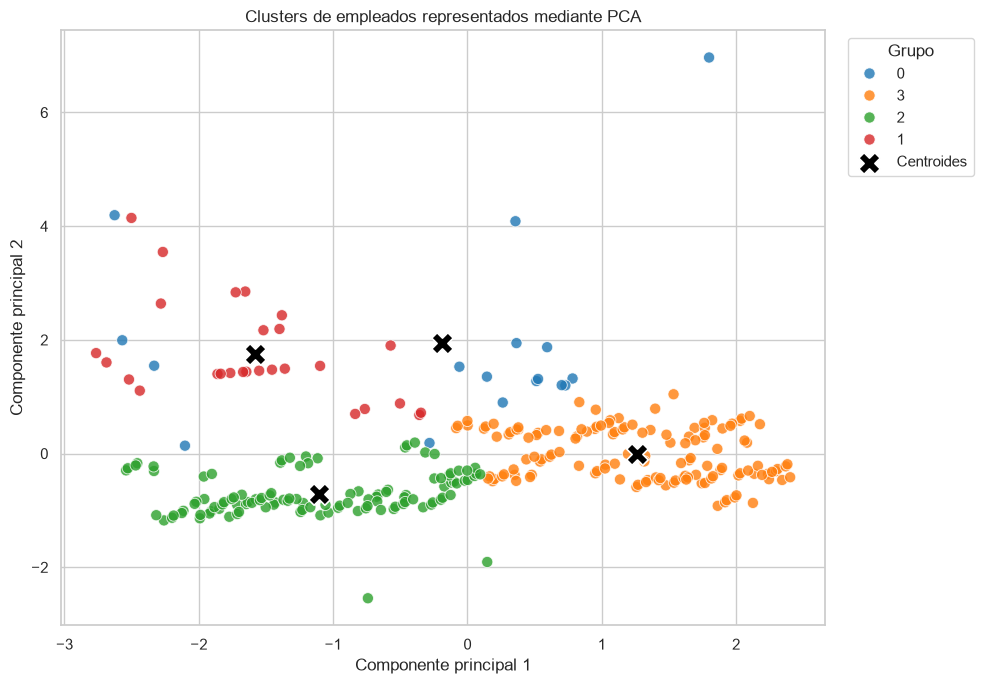

Las dos componentes representadas explican el 77.6% de la variabilidad de las variables escaladas.


In [34]:
pca = PCA(n_components=2, random_state=42)
coordenadas_pca = pca.fit_transform(X_escalado)
centroides_pca = pca.transform(modelo_kmeans.cluster_centers_)

grafico_clusters = pd.DataFrame({
    "Componente principal 1": coordenadas_pca[:, 0],
    "Componente principal 2": coordenadas_pca[:, 1],
    "Cluster": etiquetas.astype(str)
})

plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=grafico_clusters,
    x="Componente principal 1",
    y="Componente principal 2",
    hue="Cluster",
    palette="tab10",
    s=65,
    alpha=0.8
)
plt.scatter(
    centroides_pca[:, 0],
    centroides_pca[:, 1],
    marker="X",
    s=240,
    color="black",
    edgecolor="white",
    linewidth=1.2,
    label="Centroides"
)
plt.title("Clusters de empleados representados mediante PCA")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.legend(title="Grupo", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

varianza_explicada = pca.explained_variance_ratio_.sum() * 100
print(
    f"Las dos componentes representadas explican el {varianza_explicada:.1f}% "
    "de la variabilidad de las variables escaladas."
)


## 5.4 Perfil e interpretación de cada cluster

Se describen los grupos usando los promedios de las variables originales, para que las cifras se interpreten en sus unidades habituales. El tamaño de cada grupo también se incluye. Los perfiles deben interpretarse como patrones estadísticos del dataset y no como evaluaciones del desempeño de los empleados.


In [35]:
perfil_clusters = (
    resultado_cluster.groupby("Cluster")[variables_cluster]
    .agg(["mean", "median"])
    .round(2)
)
display(perfil_clusters)

tamano_clusters = (
    resultado_cluster["Cluster"]
    .value_counts()
    .sort_index()
    .rename_axis("Cluster")
    .reset_index(name="Número de empleados")
)
tamano_clusters["Porcentaje"] = (
    tamano_clusters["Número de empleados"] / len(resultado_cluster) * 100
).round(1)
display(tamano_clusters)

# Tabla sencilla de medias para facilitar la lectura de los perfiles
medias_clusters = (
    resultado_cluster.groupby("Cluster")[variables_cluster]
    .mean()
    .round(2)
)
display(medias_clusters)


Tarifa        VacationHours        SickLeaveHours         \
          mean median          mean median           mean median   
Cluster                                                            
0        53.28  43.27         46.82  61.00          45.29  51.00   
1        25.44  23.08         29.37  31.00          34.41  35.00   
2        13.39  12.45         25.86  26.00          32.68  33.00   
3        16.28  15.00         76.07  77.00          58.06  58.00   

        AntiguedadAnios         
                   mean median  
Cluster                         
0                  4.41   4.36  
1                  1.79   2.00  
2                  4.31   4.35  
3                  4.20   4.32

,Cluster,Número de empleados,Porcentaje
0,0,17,5.90
1,1,27,9.30
2,2,112,38.60
3,3,134,46.20


,Tarifa,VacationHours,SickLeaveHours,AntiguedadAnios
Cluster,,,,
0,53.28,46.82,45.29,4.41
1,25.44,29.37,34.41,1.79
2,13.39,25.86,32.68,4.31
3,16.28,76.07,58.06,4.20


In [36]:
# Generar una descripción automática y prudente de los perfiles según las medias
medias_globales = resultado_cluster[variables_cluster].mean()
for cluster_id, fila in medias_clusters.iterrows():
    rasgos = []
    for variable in variables_cluster:
        if fila[variable] > medias_globales[variable] * 1.10:
            rasgos.append(f"{variable} por encima del promedio general")
        elif fila[variable] < medias_globales[variable] * 0.90:
            rasgos.append(f"{variable} por debajo del promedio general")
    descripcion = "; ".join(rasgos) if rasgos else "valores cercanos al promedio general en las variables analizadas"
    cantidad = int((resultado_cluster["Cluster"] == cluster_id).sum())
    print(f"Cluster {cluster_id}: {cantidad} empleados; {descripcion}.")


Cluster 0: 17 empleados; Tarifa por encima del promedio general.
Cluster 1: 27 empleados; Tarifa por encima del promedio general; VacationHours por debajo del promedio general; SickLeaveHours por debajo del promedio general; AntiguedadAnios por debajo del promedio general.
Cluster 2: 112 empleados; Tarifa por debajo del promedio general; VacationHours por debajo del promedio general; SickLeaveHours por debajo del promedio general.
Cluster 3: 134 empleados; Tarifa por debajo del promedio general; VacationHours por encima del promedio general; SickLeaveHours por encima del promedio general.


## Conclusiones 5: Clustering K-Means

Al interpretar el resultado final, considera el número de empleados por grupo, los promedios de tarifa, vacaciones, licencias y antigüedad, y el valor silhouette. Un cluster con tarifa alta no implica por sí mismo mejor desempeño; únicamente indica que los empleados agrupados presentan valores similares en las variables seleccionadas.

Completa la conclusión después de ejecutar el notebook: indica el valor final de k, cuál grupo tiene la tarifa media más alta o más baja, cómo se diferencian en antigüedad y horas disponibles, y si la separación visual parece clara o presenta solapamientos.


# 6. Clustering jerárquico y comparación con K-Means

El **clustering jerárquico aglomerativo** parte de cada empleado como un grupo individual y, en cada paso, fusiona los dos grupos más cercanos hasta quedar un solo grupo. El resultado es un árbol de fusiones (**dendrograma**) que se puede "cortar" a la altura deseada para obtener el número de grupos. A diferencia de K-Means:

- no exige fijar *k* de antemano: el árbol completo se calcula una vez y *k* se decide después, mirando el dendrograma;
- es determinista (no depende de una inicialización aleatoria);
- no asume grupos esféricos de tamaño similar, aunque su costo crece con el cuadrado del número de empleados (no es un problema con ~290 registros).

Se usa la **misma matriz estandarizada** `X_escalado` de la sección 5, de forma que las diferencias entre ambos métodos se deban al algoritmo y no a los datos.

## 6.1 Implementación y elección del método de enlace

El *enlace* define cómo se mide la distancia entre dos grupos:

| Enlace | Distancia entre grupos | Tendencia |
|---|---|---|
| `ward` | aumento de la varianza interna al fusionarlos | grupos compactos y de tamaño parecido (mismo criterio que K-Means) |
| `average` | promedio de todas las distancias entre pares | intermedia |
| `complete` | distancia máxima entre pares | grupos compactos |
| `single` | distancia mínima entre pares | tiende a encadenar puntos y a aislar valores extremos |

Se calcula la matriz de enlace con `scipy.cluster.hierarchy.linkage` y se compara la **correlación cofenética** (qué tan fielmente el árbol conserva las distancias originales entre empleados). Esta correlación es una referencia, no un criterio único: se elige **Ward** por su coherencia con K-Means (ambos minimizan la varianza dentro de los grupos) y porque evita el encadenamiento de `single`.

In [37]:
n_empleados = len(X_escalado)
distancias_originales = pdist(X_escalado, metric="euclidean")

matrices_enlace = {}
filas_enlace = []
for metodo in ["ward", "average", "complete", "single"]:
    Z_metodo = linkage(X_escalado, method=metodo)   # algoritmo aglomerativo, distancia euclídea
    corr_cofenetica, _ = cophenet(Z_metodo, distancias_originales)
    matrices_enlace[metodo] = Z_metodo
    filas_enlace.append({
        "Enlace": metodo,
        "Correlación cofenética": corr_cofenetica,
        "Altura de la última fusión": Z_metodo[-1, 2],
    })

display(pd.DataFrame(filas_enlace).set_index("Enlace"))

# Matriz de enlace elegida: cada fila es una fusión [grupo A, grupo B, distancia, nº de empleados del nuevo grupo]
Z = matrices_enlace["ward"]
print(f"Matriz de enlace Ward: {Z.shape[0]} fusiones para {n_empleados} empleados.")
display(pd.DataFrame(Z[-5:], columns=["Grupo A", "Grupo B", "Distancia", "Empleados"],
                     index=[f"Fusión {i}" for i in range(Z.shape[0] - 4, Z.shape[0] + 1)]))

,Correlación cofenética,Altura de la última fusión
Enlace,,
ward,0.56,29.25
average,0.83,9.26
complete,0.78,10.51
single,0.69,3.77


Matriz de enlace Ward: 289 fusiones para 290 empleados.


,Grupo A,Grupo B,Distancia,Empleados
Fusión 285,567.00,573.00,10.42,114.00
Fusión 286,570.00,572.00,12.85,146.00
Fusión 287,560.00,575.00,13.99,148.00
Fusión 288,571.00,574.00,19.87,142.00
Fusión 289,576.00,577.00,29.25,290.00


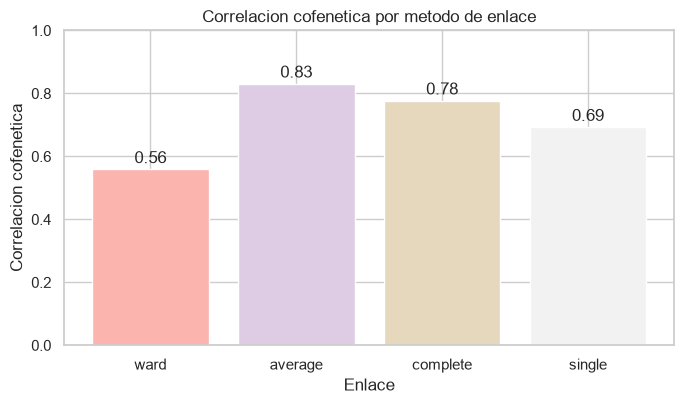

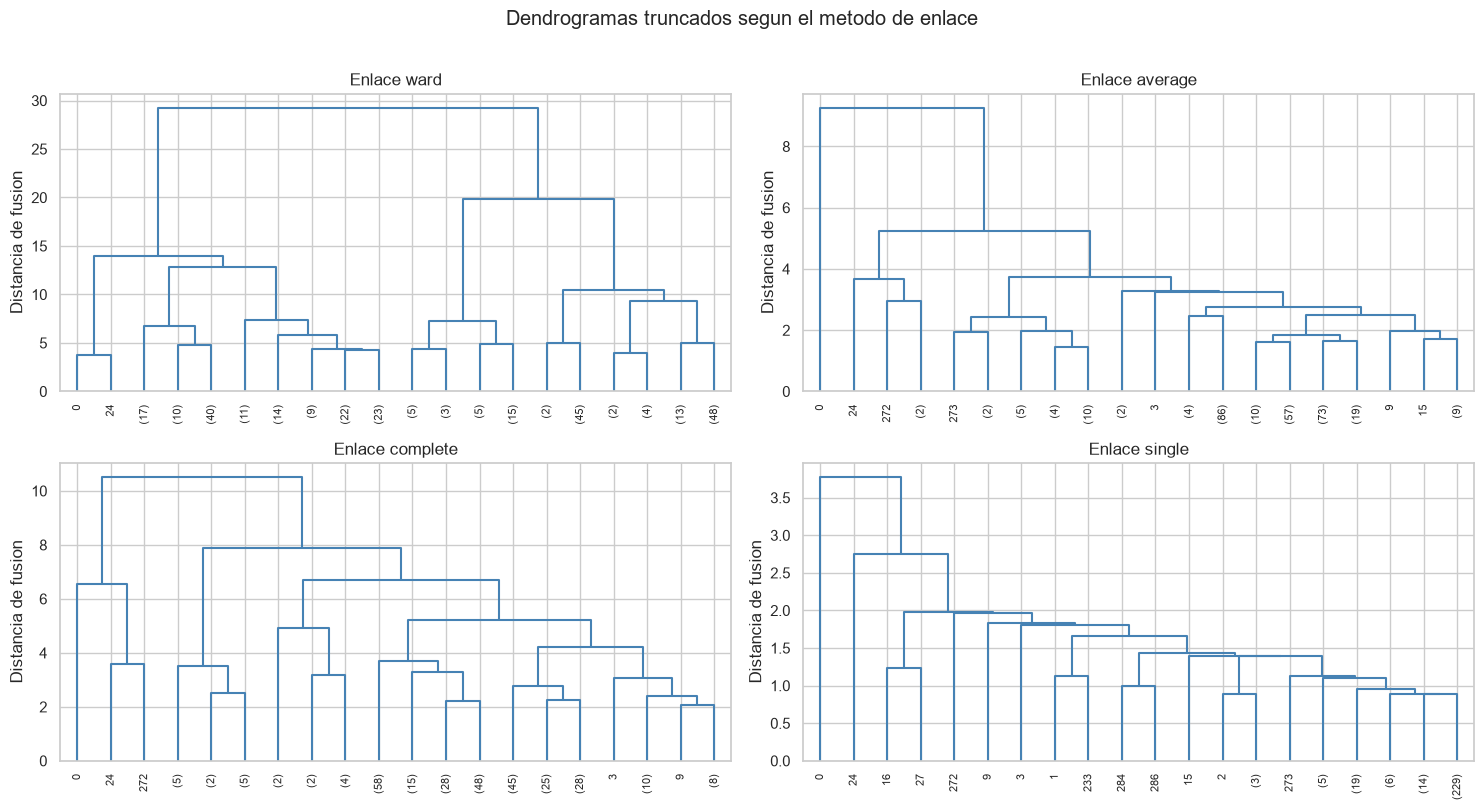

In [38]:
# Grafico 6.1: qu tan fielmente conserva cada enlace las distancias originales
tabla_enlaces = pd.DataFrame(filas_enlace).set_index("Enlace")
fig, ax = plt.subplots(figsize=(7, 4.2))
colores_enlace = plt.cm.Pastel1(np.linspace(0, 1, len(tabla_enlaces)))
barras = ax.bar(tabla_enlaces.index, tabla_enlaces.iloc[:, 0], color=colores_enlace)
ax.bar_label(barras, fmt="%.2f", padding=2)
ax.set_ylim(0, 1)
ax.set_title("Correlacion cofenetica por metodo de enlace")
ax.set_xlabel("Enlace")
ax.set_ylabel("Correlacion cofenetica")
fig.tight_layout()
plt.show()

# Forma del arbol con cada enlace (ultimas 20 fusiones): Ward da ramas equilibradas; single tiende a encadenar
fig, ejes = plt.subplots(2, 2, figsize=(15, 8))
for ax, metodo in zip(ejes.ravel(), ["ward", "average", "complete", "single"]):
    dendrogram(matrices_enlace[metodo], truncate_mode="lastp", p=20, show_leaf_counts=True,
               leaf_rotation=90, leaf_font_size=8, color_threshold=0, above_threshold_color="steelblue", ax=ax)
    ax.set_title(f"Enlace {metodo}")
    ax.set_ylabel("Distancia de fusion")
fig.suptitle("Dendrogramas truncados segun el metodo de enlace", y=1.01)
fig.tight_layout()
plt.show()

## 6.2 Dendrograma

Cada hoja es un empleado (o, en la versión truncada, un grupo de empleados); la altura a la que se unen dos ramas es la distancia entre los grupos fusionados. **Un salto grande en altura entre una fusión y la siguiente indica que se están uniendo grupos muy distintos**, por lo que cortar justo antes de ese salto da grupos naturales.

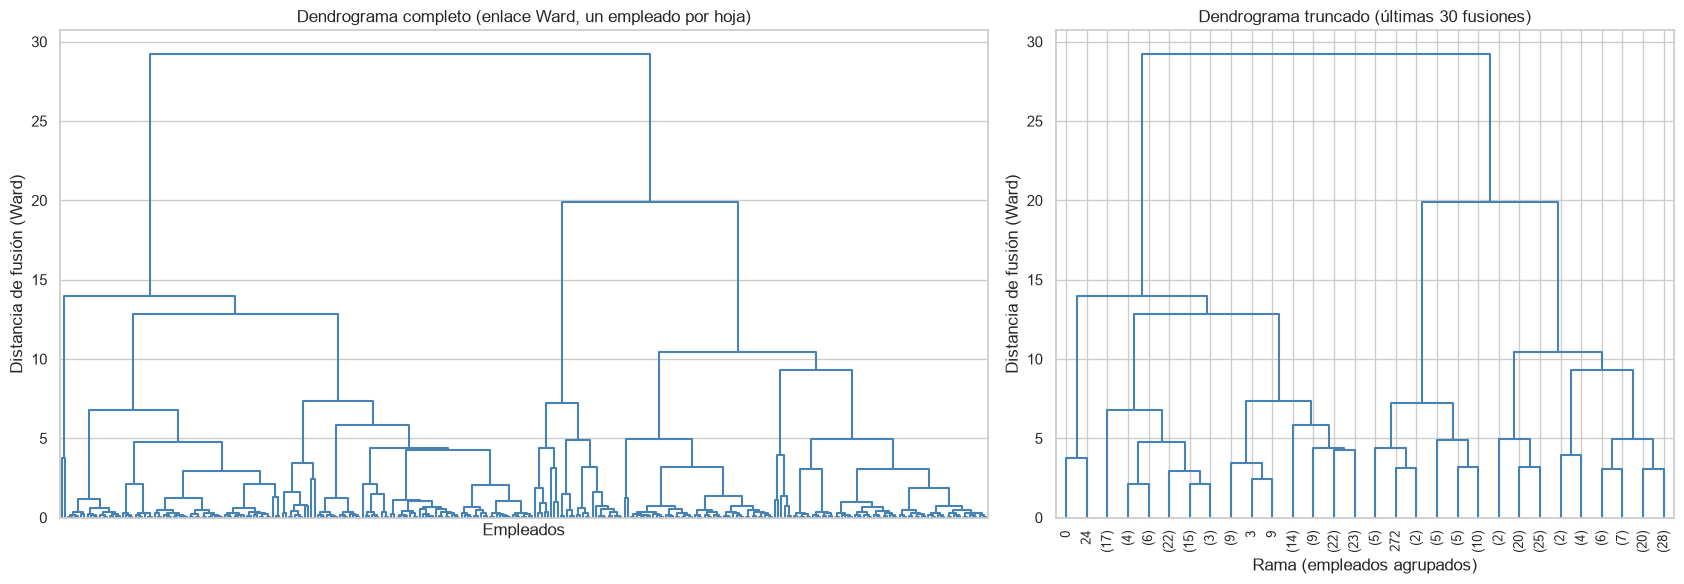

In [39]:
fig, ejes = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={"width_ratios": [1.5, 1]})

# Árbol completo (sin etiquetas: 290 hojas serían ilegibles)
dendrogram(Z, no_labels=True, color_threshold=0, above_threshold_color="steelblue", ax=ejes[0])
ejes[0].set_title("Dendrograma completo (enlace Ward, un empleado por hoja)")
ejes[0].set_xlabel("Empleados")
ejes[0].set_ylabel("Distancia de fusión (Ward)")

# Últimas 30 fusiones; el número entre paréntesis es la cantidad de empleados de cada rama
dendrogram(Z, truncate_mode="lastp", p=30, show_leaf_counts=True, leaf_rotation=90,
           leaf_font_size=9, color_threshold=0, above_threshold_color="steelblue", ax=ejes[1])
ejes[1].set_title("Dendrograma truncado (últimas 30 fusiones)")
ejes[1].set_xlabel("Rama (empleados agrupados)")
ejes[1].set_ylabel("Distancia de fusión (Ward)")

plt.tight_layout()
plt.show()

## 6.3 Determinación del número de grupos

Se usan dos criterios complementarios, además de la lectura visual del dendrograma:

1. **Salto de altura entre fusiones** (equivalente al "codo" del dendrograma): para cada *k*, diferencia entre la altura a la que se pasa de *k* a *k − 1* grupos y la altura anterior. Un salto grande significa que reducir a *k − 1* grupos obligaría a fusionar grupos muy distintos.
2. **Coeficiente silhouette** del corte en *k* grupos, el mismo indicador usado con K-Means en 5.2.

También se informa el tamaño del grupo más pequeño, porque un corte que deja grupos de uno o dos empleados suele aislar valores extremos en lugar de revelar segmentos.

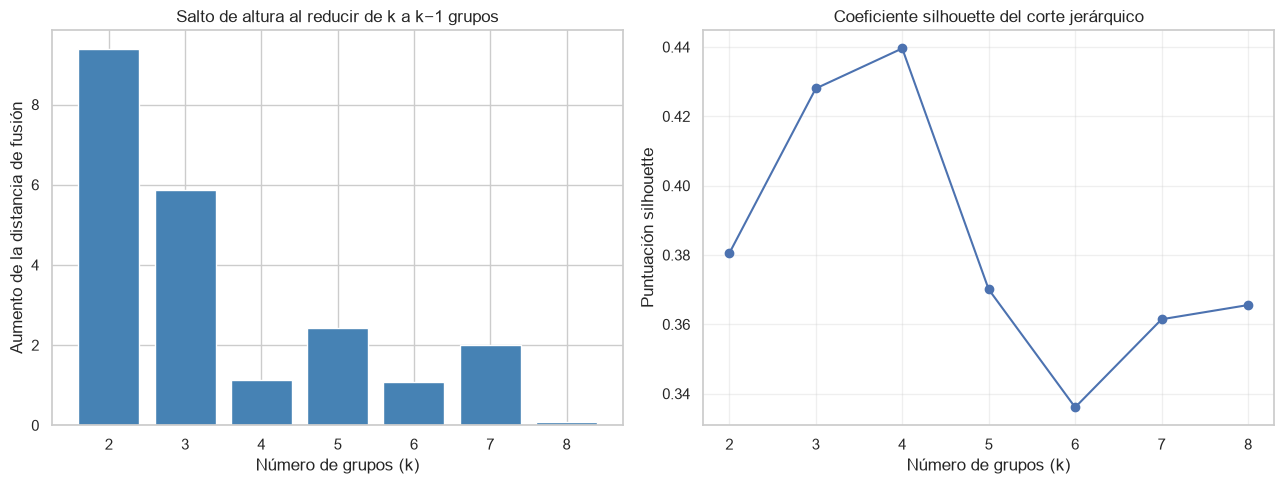

,Salto de altura,Silhouette,Grupo más pequeño
k,,,
2,9.38,0.38,142
3,5.88,0.43,28
4,1.14,0.44,2
5,2.44,0.37,2
6,1.09,0.34,2
7,2.01,0.36,2
8,0.09,0.37,2


Mayor salto de altura: k = 2 | Mayor silhouette: k = 4


In [40]:
k_maximo_jer = min(8, n_empleados - 1)
valores_k_jer = list(range(2, k_maximo_jer + 1))

filas_k = []
for k in valores_k_jer:
    # Pasar de k a k-1 grupos es la fusión número (n - k); la anterior deja k grupos
    salto = Z[n_empleados - k, 2] - Z[n_empleados - k - 1, 2]
    etiquetas_k = fcluster(Z, t=k, criterion="maxclust")
    filas_k.append({
        "k": k,
        "Salto de altura": salto,
        "Silhouette": silhouette_score(X_escalado, etiquetas_k),
        "Grupo más pequeño": int(np.bincount(etiquetas_k)[1:].min()),
    })
tabla_k_jer = pd.DataFrame(filas_k)

fig, ejes = plt.subplots(1, 2, figsize=(13, 5))
ejes[0].bar(tabla_k_jer["k"], tabla_k_jer["Salto de altura"], color="steelblue")
ejes[0].set_title("Salto de altura al reducir de k a k−1 grupos")
ejes[0].set_xlabel("Número de grupos (k)")
ejes[0].set_ylabel("Aumento de la distancia de fusión")
ejes[0].set_xticks(valores_k_jer)

ejes[1].plot(tabla_k_jer["k"], tabla_k_jer["Silhouette"], marker="o")
ejes[1].set_title("Coeficiente silhouette del corte jerárquico")
ejes[1].set_xlabel("Número de grupos (k)")
ejes[1].set_ylabel("Puntuación silhouette")
ejes[1].set_xticks(valores_k_jer)
ejes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

display(tabla_k_jer.set_index("k"))

k_por_salto = int(tabla_k_jer.loc[tabla_k_jer["Salto de altura"].idxmax(), "k"])
k_por_silhouette = int(tabla_k_jer.loc[tabla_k_jer["Silhouette"].idxmax(), "k"])
print(f"Mayor salto de altura: k = {k_por_salto} | Mayor silhouette: k = {k_por_silhouette}")

**Criterio de decisión.** El mayor salto de altura casi siempre favorece valores muy pequeños de *k* (las últimas fusiones son por naturaleza las más costosas), por lo que se contrasta con silhouette y con el tamaño del grupo más pequeño. Por defecto se usa el *k* de mayor silhouette; la celda siguiente permite fijar otro valor si el dendrograma y la utilidad de los perfiles lo justifican.

## 6.4 Grupos finales y dendrograma con la línea de corte

Número de grupos jerárquicos: 4 | altura de corte: 13.42
Coincidencia con AgglomerativeClustering de scikit-learn (ARI): 1.000
Silhouette del corte jerárquico: 0.440


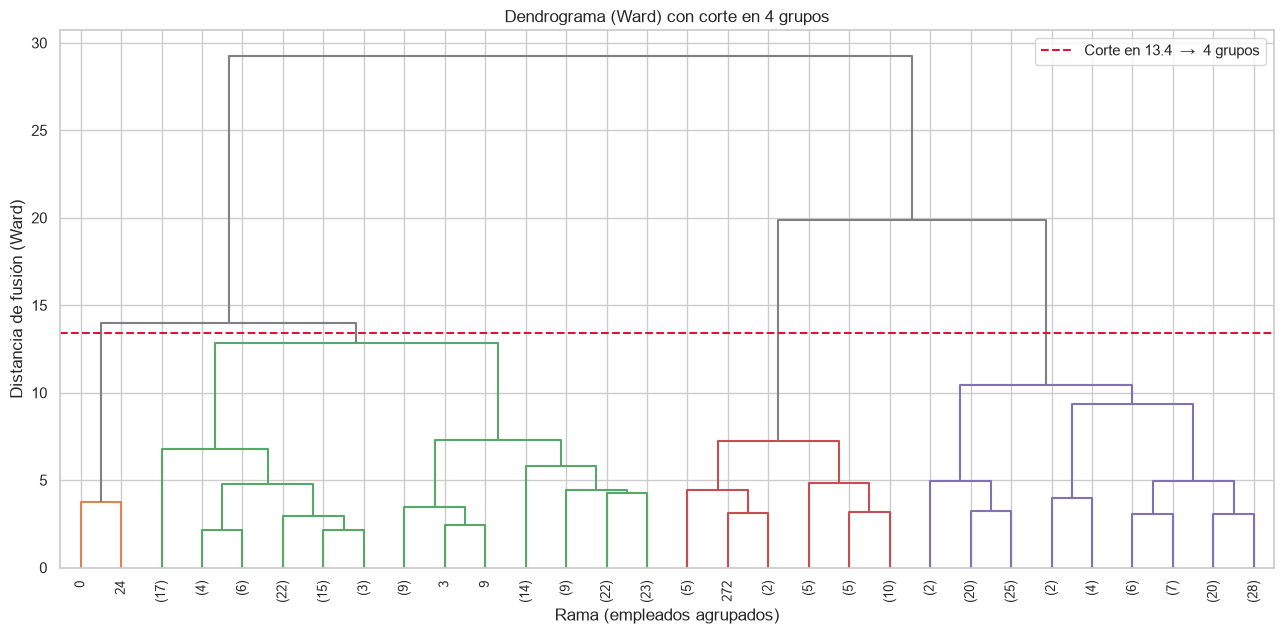

Dendrograma guardado como dendrograma_jerarquico.png


In [41]:
# Ajusta este valor después de revisar el dendrograma y la tabla anterior.
k_jerarquico = k_por_silhouette

# Altura de corte: punto medio entre la fusión que deja k grupos y la siguiente (que los reduciría a k-1)
altura_corte = (Z[n_empleados - k_jerarquico - 1, 2] + Z[n_empleados - k_jerarquico, 2]) / 2
etiquetas_jer = fcluster(Z, t=altura_corte, criterion="distance") - 1   # etiquetas 0..k-1

# Verificación cruzada con la implementación de scikit-learn (debe coincidir exactamente)
etiquetas_sklearn = AgglomerativeClustering(n_clusters=k_jerarquico, linkage="ward").fit_predict(X_escalado)
ari_verificacion = adjusted_rand_score(etiquetas_jer, etiquetas_sklearn)
print(f"Número de grupos jerárquicos: {k_jerarquico} | altura de corte: {altura_corte:.2f}")
print(f"Coincidencia con AgglomerativeClustering de scikit-learn (ARI): {ari_verificacion:.3f}")
print(f"Silhouette del corte jerárquico: {silhouette_score(X_escalado, etiquetas_jer):.3f}")

fig, ax = plt.subplots(figsize=(13, 6.5))
dendrogram(Z, truncate_mode="lastp", p=30, show_leaf_counts=True, leaf_rotation=90, leaf_font_size=9,
           color_threshold=altura_corte, above_threshold_color="gray", ax=ax)
ax.axhline(altura_corte, color="crimson", ls="--", lw=1.5,
           label=f"Corte en {altura_corte:.1f}  →  {k_jerarquico} grupos")
ax.set_title(f"Dendrograma (Ward) con corte en {k_jerarquico} grupos")
ax.set_xlabel("Rama (empleados agrupados)")
ax.set_ylabel("Distancia de fusión (Ward)")
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig("dendrograma_jerarquico.png", dpi=150, bbox_inches="tight")
plt.show()
print("Dendrograma guardado como dendrograma_jerarquico.png")

In [42]:
resultado_jer = datos_modelado.loc[datos_cluster.index].copy()
resultado_jer["ClusterJerarquico"] = etiquetas_jer

perfil_jer = resultado_jer.groupby("ClusterJerarquico")[variables_cluster].mean().round(2)
perfil_jer.insert(0, "Empleados", resultado_jer["ClusterJerarquico"].value_counts().sort_index())
perfil_jer.insert(1, "Porcentaje", (perfil_jer["Empleados"] / len(resultado_jer) * 100).round(1))
display(perfil_jer)

medias_globales_jer = resultado_jer[variables_cluster].mean()
for cluster_id, fila in perfil_jer.iterrows():
    rasgos = []
    for variable in variables_cluster:
        if fila[variable] > medias_globales_jer[variable] * 1.10:
            rasgos.append(f"{variable} por encima del promedio general")
        elif fila[variable] < medias_globales_jer[variable] * 0.90:
            rasgos.append(f"{variable} por debajo del promedio general")
    descripcion = "; ".join(rasgos) if rasgos else "valores cercanos al promedio general"
    print(f"Grupo jerárquico {cluster_id}: {int(fila['Empleados'])} empleados; {descripcion}.")

,Empleados,Porcentaje,Tarifa,VacationHours,SickLeaveHours,AntiguedadAnios
ClusterJerarquico,,,,,,
0,2,0.70,104.82,81.50,60.50,4.34
1,146,50.30,18.52,74.06,57.28,4.22
2,28,9.70,27.10,28.68,34.07,1.80
3,114,39.30,14.05,25.43,32.46,4.33


Grupo jerárquico 0: 2 empleados; Tarifa por encima del promedio general; VacationHours por encima del promedio general; SickLeaveHours por encima del promedio general.
Grupo jerárquico 1: 146 empleados; VacationHours por encima del promedio general; SickLeaveHours por encima del promedio general.
Grupo jerárquico 2: 28 empleados; Tarifa por encima del promedio general; VacationHours por debajo del promedio general; SickLeaveHours por debajo del promedio general; AntiguedadAnios por debajo del promedio general.
Grupo jerárquico 3: 114 empleados; Tarifa por debajo del promedio general; VacationHours por debajo del promedio general; SickLeaveHours por debajo del promedio general.


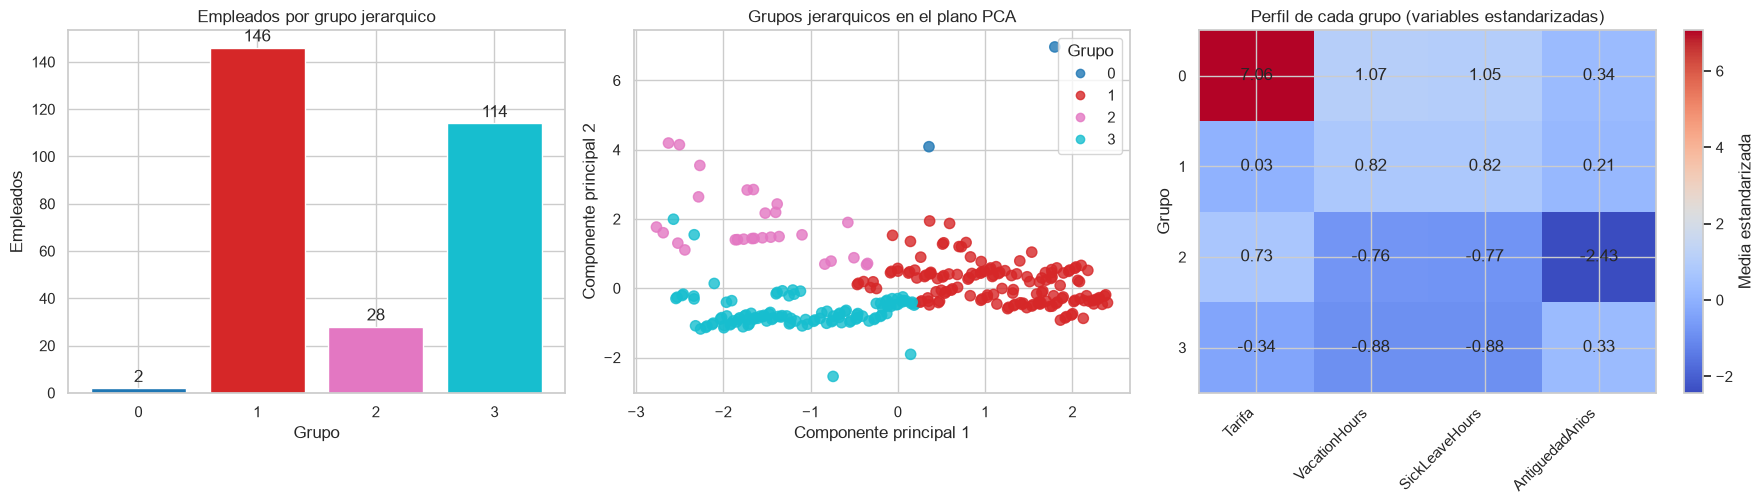

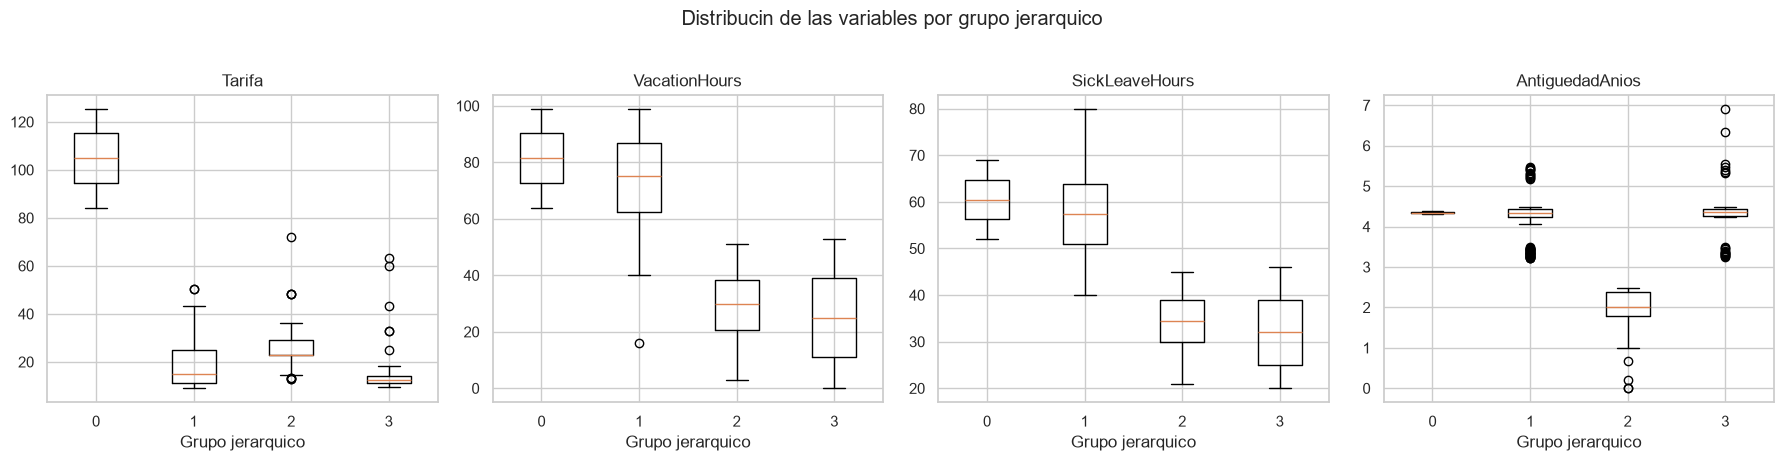

In [43]:
# Graficos 6.4: tamano, perfil estandarizado y distribucion de cada variable por grupo jerarquico
Z_perfil_jer = (pd.DataFrame(X_escalado, columns=variables_cluster, index=resultado_jer.index)
                .groupby(resultado_jer["ClusterJerarquico"]).mean())

fig, ejes = plt.subplots(1, 3, figsize=(18, 5.2), gridspec_kw={"width_ratios": [1, 1, 1.15]})

# a) Tamao de cada grupo
tam_jer_plot = resultado_jer["ClusterJerarquico"].value_counts().sort_index()
colores_grupos = plt.cm.tab10(np.linspace(0, 1, len(tam_jer_plot)))
barras = ejes[0].bar(tam_jer_plot.index.astype(str), tam_jer_plot.values, color=colores_grupos)
ejes[0].bar_label(barras, padding=2)
ejes[0].set_title("Empleados por grupo jerarquico")
ejes[0].set_xlabel("Grupo")
ejes[0].set_ylabel("Empleados")

# b) Dispersion en el plano PCA (mismos ejes que en 5.3)
scatter = ejes[1].scatter(coordenadas_pca[:, 0], coordenadas_pca[:, 1], c=etiquetas_jer,
                          cmap="tab10", s=55, alpha=0.8)
ejes[1].set_title("Grupos jerarquicos en el plano PCA")
ejes[1].set_xlabel("Componente principal 1")
ejes[1].set_ylabel("Componente principal 2")
ejes[1].legend(*scatter.legend_elements(), title="Grupo")

# c) Perfil en unidades estandarizadas: >0 = por encima del promedio general, <0 = por debajo
imagen = ejes[2].imshow(Z_perfil_jer.to_numpy(), cmap="coolwarm", aspect="auto")
ejes[2].set_xticks(np.arange(len(Z_perfil_jer.columns)), labels=Z_perfil_jer.columns, rotation=45, ha="right")
ejes[2].set_yticks(np.arange(len(Z_perfil_jer.index)), labels=Z_perfil_jer.index)
for fila in range(Z_perfil_jer.shape[0]):
    for columna in range(Z_perfil_jer.shape[1]):
        imagen_valor = Z_perfil_jer.iloc[fila, columna]
        ejes[2].text(columna, fila, f"{imagen_valor:.2f}", ha="center", va="center")
ejes[2].set_title("Perfil de cada grupo (variables estandarizadas)")
ejes[2].set_xlabel("")
ejes[2].set_ylabel("Grupo")
fig.colorbar(imagen, ax=ejes[2], label="Media estandarizada")
fig.tight_layout()
plt.show()

# d) Distribucin de cada variable original por grupo
grupos_jer = sorted(resultado_jer["ClusterJerarquico"].unique())
fig, ejes = plt.subplots(1, len(variables_cluster), figsize=(18, 4.5))
for ax, variable in zip(ejes, variables_cluster):
    datos_por_grupo = [resultado_jer.loc[resultado_jer["ClusterJerarquico"] == grupo, variable].to_numpy()
                       for grupo in grupos_jer]
    ax.boxplot(datos_por_grupo)
    ax.set_xticks(np.arange(1, len(grupos_jer) + 1), labels=grupos_jer)
    ax.set_title(variable)
    ax.set_xlabel("Grupo jerarquico")
fig.suptitle("Distribucin de las variables por grupo jerarquico", y=1.02)
fig.tight_layout()
plt.show()

## 6.5 Comparación con K-Means

Para comparar de forma justa se cortan los dos métodos en el **mismo número de grupos** (el *k* final de K-Means, sección 5.2). Si el *k* jerárquico elegido es distinto, se informa además su resultado propio. Se usan:

- **ARI (índice de Rand ajustado):** 1 = particiones idénticas, ~0 = coincidencia como la del azar. No depende de cómo se numeren los grupos.
- **NMI (información mutua normalizada):** 0 a 1; cuánta información comparten las dos particiones.
- **Tabla de contingencia:** cuántos empleados de cada grupo K-Means cayeron en cada grupo jerárquico.
- **Métricas internas:** silhouette (↑ mejor), Davies-Bouldin (↓ mejor) y Calinski-Harabasz (↑ mejor).

Las etiquetas numéricas de cada método son arbitrarias (el grupo 0 de K-Means no tiene por qué ser el grupo 0 del jerárquico); por eso se emparejan los grupos con el algoritmo húngaro, que maximiza el número de empleados que coinciden.

Comparacion con k = 4 grupos en ambos metodos
  ARI = 0.798 | NMI = 0.750
  Empleados asignados al grupo equivalente: 266 de 290 (91.7 %)


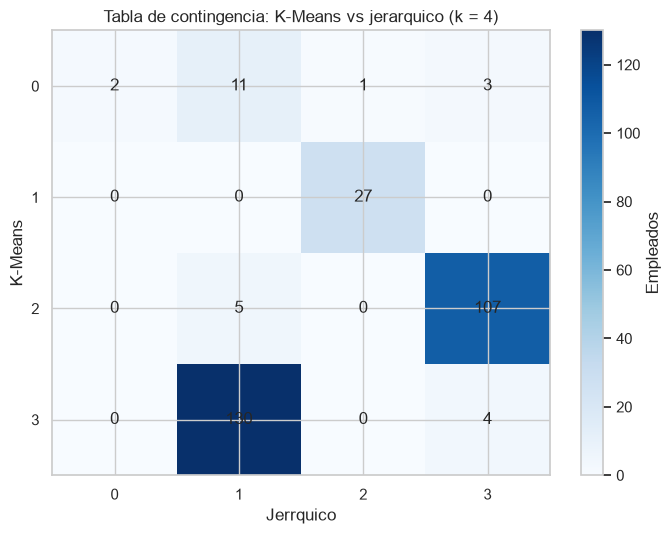

,k,Silhouette,Davies-Bouldin,Calinski-Harabasz,Grupo mas pequeno,Grupo mas grande
Metodo,,,,,,
K-Means (k=4),4,0.46,0.88,178.44,17,134
Jerrquico Ward (k=4),4,0.44,0.72,157.66,2,146


In [44]:
# Corte jerarquico con el mismo k que K-Means
etiquetas_jer_mismo_k = fcluster(Z, t=k_final, criterion="maxclust") - 1
etiquetas_km = etiquetas  # K-Means, seccion 5.2

# --- Metricas de acuerdo entre particiones
ari = adjusted_rand_score(etiquetas_km, etiquetas_jer_mismo_k)
nmi = normalized_mutual_info_score(etiquetas_km, etiquetas_jer_mismo_k)

# --- Tabla de contingencia y emparejamiento de grupos
contingencia = pd.crosstab(pd.Series(etiquetas_km, name="K-Means"),
                           pd.Series(etiquetas_jer_mismo_k, name="Jerrquico"))
fila_i, col_j = linear_sum_assignment(-contingencia.values)
mapa_jer_a_km = {contingencia.columns[c]: contingencia.index[r] for r, c in zip(fila_i, col_j)}
etiquetas_jer_alineadas = pd.Series(etiquetas_jer_mismo_k).map(mapa_jer_a_km).fillna(-1).astype(int).to_numpy()
coinciden = etiquetas_jer_alineadas == etiquetas_km
print(f"Comparacion con k = {k_final} grupos en ambos metodos")
print(f"  ARI = {ari:.3f} | NMI = {nmi:.3f}")
print(f"  Empleados asignados al grupo equivalente: {coinciden.sum()} de {len(coinciden)} ({coinciden.mean() * 100:.1f} %)")

fig, ax = plt.subplots(figsize=(7, 5.5))
matriz = contingencia.to_numpy()
imagen = ax.imshow(matriz, cmap="Blues", aspect="auto")
ax.set_xticks(np.arange(len(contingencia.columns)), labels=contingencia.columns)
ax.set_yticks(np.arange(len(contingencia.index)), labels=contingencia.index)
ax.set_xlabel("Jerrquico")
ax.set_ylabel("K-Means")
ax.set_title(f"Tabla de contingencia: K-Means vs jerarquico (k = {k_final})")
for fila in range(matriz.shape[0]):
    for columna in range(matriz.shape[1]):
        ax.text(columna, fila, str(matriz[fila, columna]), ha="center", va="center")
fig.colorbar(imagen, ax=ax, label="Empleados")
fig.tight_layout()
fig.savefig("comparacion_contingencia_kmeans_jerarquico.png", dpi=180, bbox_inches="tight")
plt.show()

# --- Metricas internas
def metricas_internas(nombre, etiquetas_x):
    tamanos = np.bincount(etiquetas_x)
    return {
        "Metodo": nombre,
        "k": len(np.unique(etiquetas_x)),
        "Silhouette": silhouette_score(X_escalado, etiquetas_x),
        "Davies-Bouldin": davies_bouldin_score(X_escalado, etiquetas_x),
        "Calinski-Harabasz": calinski_harabasz_score(X_escalado, etiquetas_x),
        "Grupo mas pequeno": int(tamanos.min()),
        "Grupo mas grande": int(tamanos.max()),
    }

filas_metricas = [metricas_internas(f"K-Means (k={k_final})", etiquetas_km),
                  metricas_internas(f"Jerrquico Ward (k={k_final})", etiquetas_jer_mismo_k)]
if k_jerarquico != k_final:
    filas_metricas.append(metricas_internas(f"Jerrquico Ward (k={k_jerarquico}, elegido en 6.3)", etiquetas_jer))
display(pd.DataFrame(filas_metricas).set_index("Metodo"))

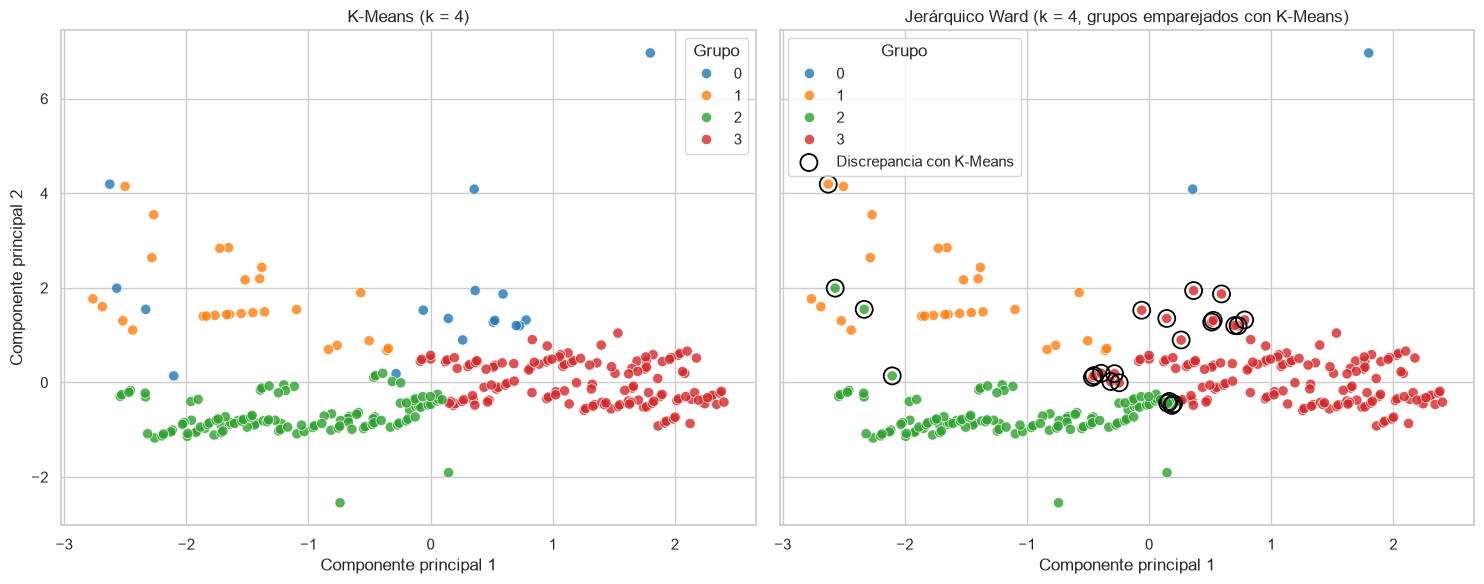

In [45]:
# Representación PCA con los mismos ejes para ambos métodos (solo visualización, igual que en 5.3)
fig, ejes = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)
for ax, etiquetas_x, titulo in [
    (ejes[0], etiquetas_km, f"K-Means (k = {k_final})"),
    (ejes[1], etiquetas_jer_alineadas, f"Jerárquico Ward (k = {k_final}, grupos emparejados con K-Means)"),
]:
    sns.scatterplot(x=coordenadas_pca[:, 0], y=coordenadas_pca[:, 1], hue=etiquetas_x.astype(str),
                    hue_order=[str(g) for g in sorted(np.unique(etiquetas_km))],
                    palette="tab10", s=55, alpha=0.8, ax=ax)
    ax.set_title(titulo)
    ax.set_xlabel("Componente principal 1")
    ax.set_ylabel("Componente principal 2")
    ax.legend(title="Grupo")

# Marca los empleados que cada método ubica en grupos no equivalentes
ejes[1].scatter(coordenadas_pca[~coinciden, 0], coordenadas_pca[~coinciden, 1], s=150, facecolors="none",
                edgecolors="black", linewidths=1.3, label="Discrepancia con K-Means")
ejes[1].legend(title="Grupo")
plt.tight_layout()
plt.show()

In [46]:
# Perfiles de ambos métodos, con los grupos jerárquicos renombrados al grupo K-Means equivalente
resultado_comparacion = resultado_cluster[["BusinessEntityID"] + variables_cluster].copy()
resultado_comparacion["KMeans"] = etiquetas_km
resultado_comparacion["Jerarquico"] = etiquetas_jer_alineadas

perfil_km_c = resultado_comparacion.groupby("KMeans")[variables_cluster].mean().round(2)
perfil_km_c.insert(0, "Empleados", resultado_comparacion["KMeans"].value_counts().sort_index())
perfil_jer_c = resultado_comparacion.groupby("Jerarquico")[variables_cluster].mean().round(2)
perfil_jer_c.insert(0, "Empleados", resultado_comparacion["Jerarquico"].value_counts().sort_index())

print("Perfil medio por grupo — K-Means")
display(perfil_km_c)
print("Perfil medio por grupo — Jerárquico (mismo número de grupo = grupo equivalente de K-Means)")
display(perfil_jer_c)

discrepantes = resultado_comparacion.loc[~coinciden]
print(f"Empleados que cada método ubica en grupos no equivalentes: {len(discrepantes)}")
if len(discrepantes):
    display(discrepantes.head(15))
    print("Promedios de los empleados discrepantes frente al total:")
    display(pd.DataFrame({"Discrepantes": discrepantes[variables_cluster].mean(),
                          "Todos": resultado_comparacion[variables_cluster].mean()}).round(2))

Perfil medio por grupo — K-Means


,Empleados,Tarifa,VacationHours,SickLeaveHours,AntiguedadAnios
KMeans,,,,,
0,17,53.28,46.82,45.29,4.41
1,27,25.44,29.37,34.41,1.79
2,112,13.39,25.86,32.68,4.31
3,134,16.28,76.07,58.06,4.20


Perfil medio por grupo — Jerárquico (mismo número de grupo = grupo equivalente de K-Means)


,Empleados,Tarifa,VacationHours,SickLeaveHours,AntiguedadAnios
Jerarquico,,,,,
0,2,104.82,81.50,60.50,4.34
1,28,27.10,28.68,34.07,1.80
2,114,14.05,25.43,32.46,4.33
3,146,18.52,74.06,57.28,4.22


Empleados que cada método ubica en grupos no equivalentes: 24


,BusinessEntityID,Tarifa,VacationHours,SickLeaveHours,AntiguedadAnios,KMeans,Jerarquico
1,2,63.46,1,20,5.33,0,2
2,3,43.27,2,21,5.55,0,2
6,7,50.48,61,50,4.30,0,3
7,8,40.87,62,51,4.42,0,3
8,9,40.87,63,51,4.37,0,3
9,10,42.48,16,64,4.07,0,3
15,16,37.50,40,40,5.44,0,3
25,26,24.52,43,41,4.49,2,3
133,134,25.00,40,40,4.37,2,3
151,152,25.00,41,40,4.32,2,3


Promedios de los empleados discrepantes frente al total:


,Discrepantes,Todos
Tarifa,36.55,18.19
VacationHours,43.88,50.61
SickLeaveHours,43.21,45.31
AntiguedadAnios,4.41,4.03


C:\Users\Daniel\AppData\Local\Temp\ipykernel_29776\2259978620.py:18: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


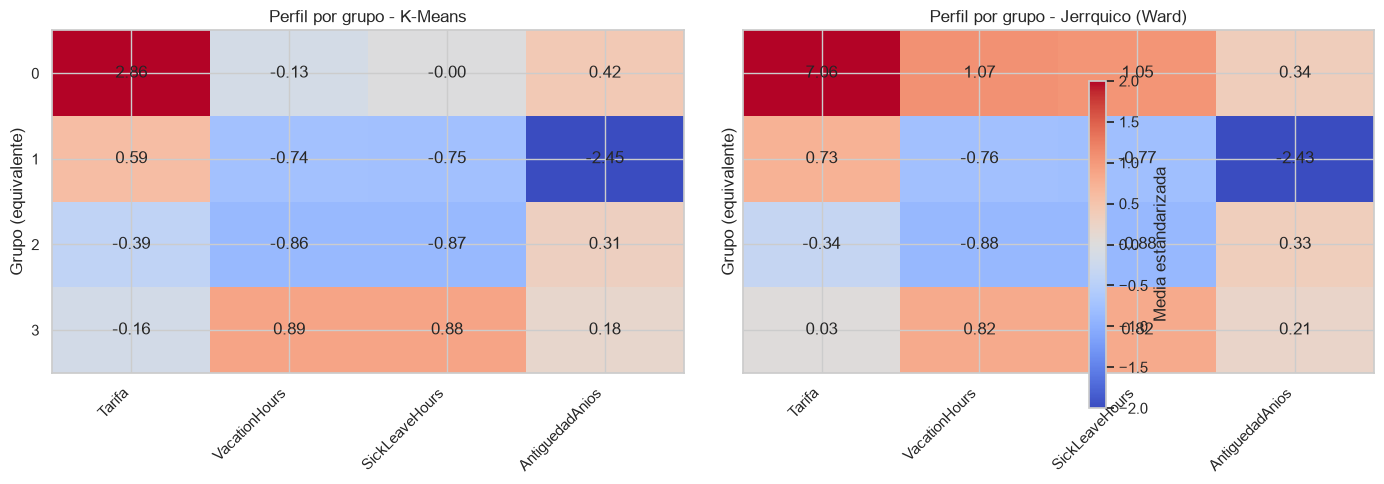

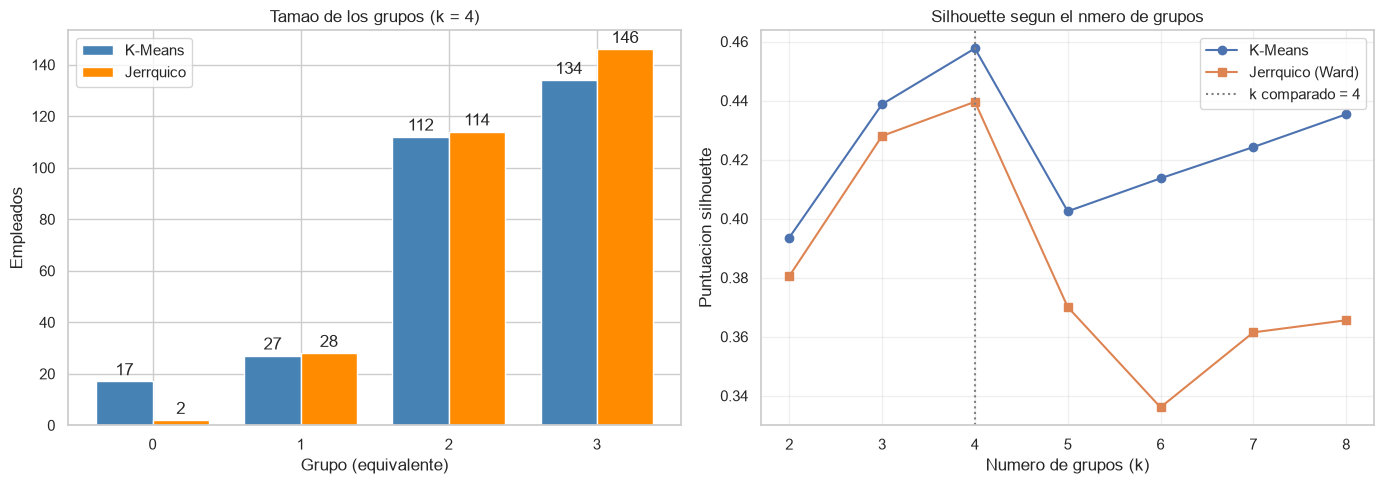

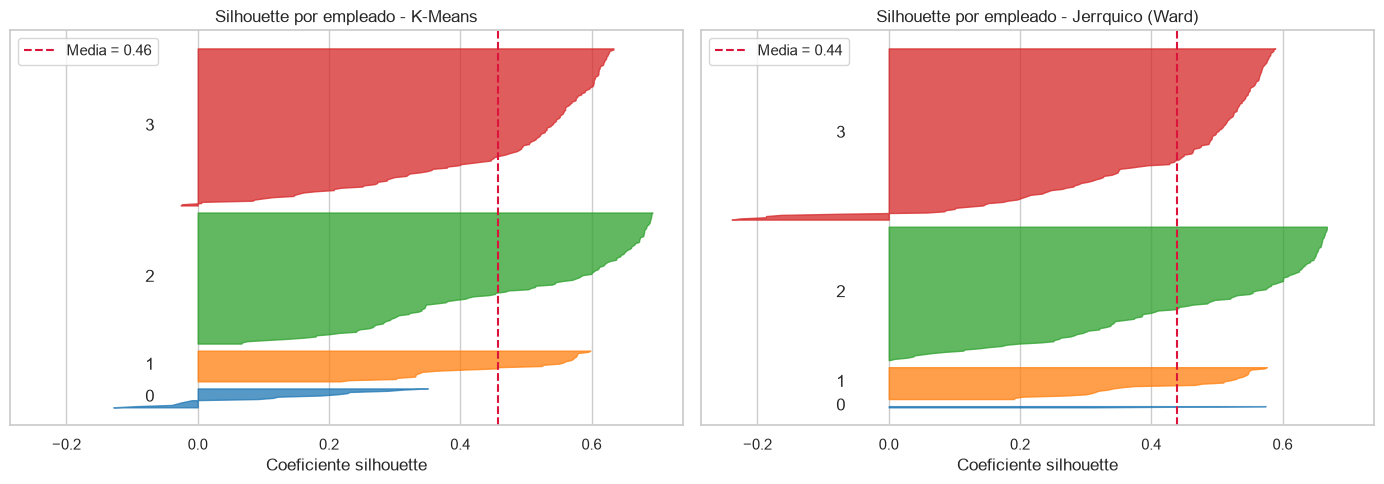

In [47]:
# Graficos 6.5 (a): perfiles estandarizados de ambos metodos con la misma escala de color
Z_df = pd.DataFrame(X_escalado, columns=variables_cluster, index=resultado_comparacion.index)
z_km = Z_df.groupby(resultado_comparacion["KMeans"]).mean()
z_jer = Z_df.groupby(resultado_comparacion["Jerarquico"]).mean()

fig, ejes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, tabla_z, titulo in [(ejes[0], z_km, "K-Means"), (ejes[1], z_jer, "Jerrquico (Ward)")]:
    imagen = ax.imshow(tabla_z.to_numpy(), cmap="coolwarm", vmin=-2, vmax=2, aspect="auto")
    ax.set_xticks(np.arange(len(tabla_z.columns)), labels=tabla_z.columns, rotation=45, ha="right")
    ax.set_yticks(np.arange(len(tabla_z.index)), labels=tabla_z.index)
    for fila in range(tabla_z.shape[0]):
        for columna in range(tabla_z.shape[1]):
            ax.text(columna, fila, f"{tabla_z.iloc[fila, columna]:.2f}", ha="center", va="center")
    ax.set_title(f"Perfil por grupo - {titulo}")
    ax.set_xlabel("")
    ax.set_ylabel("Grupo (equivalente)")
fig.colorbar(imagen, ax=ejes, label="Media estandarizada", shrink=0.85)
fig.tight_layout()
fig.savefig("comparacion_perfiles_kmeans_jerarquico.png", dpi=180, bbox_inches="tight")
plt.show()

# Graficos 6.5 (b): tamano de los grupos y silhouette en funcion de k para ambos metodos
tamanos_comp = pd.DataFrame({
    "K-Means": resultado_comparacion["KMeans"].value_counts().sort_index(),
    "Jerrquico": resultado_comparacion["Jerarquico"].value_counts().sort_index(),
}).fillna(0).astype(int)

fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
x = np.arange(len(tamanos_comp.index))
bar_width = 0.38
barras_km = ejes[0].bar(x - bar_width / 2, tamanos_comp["K-Means"], width=bar_width,
                         color="steelblue", label="K-Means")
barras_jer = ejes[0].bar(x + bar_width / 2, tamanos_comp["Jerrquico"], width=bar_width,
                          color="darkorange", label="Jerrquico")
ejes[0].bar_label(barras_km, padding=2)
ejes[0].bar_label(barras_jer, padding=2)
ejes[0].set_xticks(x, labels=tamanos_comp.index)
ejes[0].set_title(f"Tamao de los grupos (k = {k_final})")
ejes[0].set_xlabel("Grupo (equivalente)")
ejes[0].set_ylabel("Empleados")
ejes[0].legend()

ejes[1].plot(valores_k, siluetas, marker="o", label="K-Means")
ejes[1].plot(tabla_k_jer["k"], tabla_k_jer["Silhouette"], marker="s", label="Jerrquico (Ward)")
ejes[1].axvline(k_final, color="gray", ls=":", label=f"k comparado = {k_final}")
ejes[1].set_title("Silhouette segun el nmero de grupos")
ejes[1].set_xlabel("Numero de grupos (k)")
ejes[1].set_ylabel("Puntuacion silhouette")
ejes[1].set_xticks(valores_k)
ejes[1].grid(True, alpha=0.3)
ejes[1].legend()
fig.tight_layout()
fig.savefig("comparacion_tamanos_silhouette.png", dpi=180, bbox_inches="tight")
plt.show()

# Graficos 6.5 (c): silhouette de cada empleado (qu tan bien encaja en su grupo) con ambos metodos
from sklearn.metrics import silhouette_samples
fig, ejes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)
for ax, etiquetas_x, titulo in [(ejes[0], etiquetas_km, "K-Means"),
                                (ejes[1], etiquetas_jer_alineadas, "Jerrquico (Ward)")]:
    valores_sil = silhouette_samples(X_escalado, etiquetas_x)
    y_inferior = 5
    for g in sorted(np.unique(etiquetas_x)):
        v = np.sort(valores_sil[etiquetas_x == g])
        ax.fill_betweenx(np.arange(y_inferior, y_inferior + len(v)), 0, v, alpha=0.75,
                         color=plt.cm.tab10(g % 10))
        ax.text(-0.08, y_inferior + len(v) / 2, str(g), va="center")
        y_inferior += len(v) + 5
    ax.axvline(valores_sil.mean(), color="crimson", ls="--", label=f"Media = {valores_sil.mean():.2f}")
    ax.set_title(f"Silhouette por empleado - {titulo}")
    ax.set_xlabel("Coeficiente silhouette")
    ax.set_yticks([])
    ax.legend()
fig.tight_layout()
fig.savefig("comparacion_silhouette_empleados.png", dpi=180, bbox_inches="tight")
plt.show()

## 6.6 Conclusiones del clustering jerárquico y comparación

La celda siguiente resume con cifras reales los resultados de las secciones 6.3 a 6.5 para que la conclusión se base siempre en la última ejecución.

In [48]:
def interpretar_ari(valor):
    if valor >= 0.90:
        return "las dos particiones son prácticamente idénticas"
    if valor >= 0.70:
        return "hay un acuerdo alto: los métodos coinciden en la estructura general y difieren en los límites de algunos grupos"
    if valor >= 0.40:
        return "hay un acuerdo moderado: comparten parte de la estructura, pero agrupan de forma distinta a una fracción relevante de empleados"
    return "el acuerdo es bajo: los métodos describen estructuras distintas"

sil_km = silhouette_score(X_escalado, etiquetas_km)
sil_jer = silhouette_score(X_escalado, etiquetas_jer_mismo_k)
mejor = "K-Means" if sil_km > sil_jer else "el clustering jerárquico"

print(f"• Número de grupos: K-Means k = {k_final}; dendrograma — mayor salto en k = {k_por_salto}, "
      f"mayor silhouette en k = {k_por_silhouette}, elegido k = {k_jerarquico}.")
print(f"• Acuerdo entre métodos con k = {k_final}: ARI = {ari:.2f} y NMI = {nmi:.2f}; {interpretar_ari(ari)}.")
print(f"• {coinciden.sum()} de {len(coinciden)} empleados ({coinciden.mean() * 100:.1f} %) quedan en el grupo equivalente; "
      f"{(~coinciden).sum()} cambian de grupo según el método.")
print(f"• Calidad interna con k = {k_final}: silhouette K-Means = {sil_km:.3f} vs jerárquico = {sil_jer:.3f}; "
      f"{mejor} obtiene grupos más compactos y separados según esta métrica (la diferencia puede ser pequeña).")
tam_km = np.bincount(etiquetas_km)
tam_jer = np.bincount(etiquetas_jer_mismo_k)
print(f"• Tamaños de grupo — K-Means: {sorted(tam_km.tolist(), reverse=True)} | jerárquico: {sorted(tam_jer.tolist(), reverse=True)}.")
print("• Estos perfiles describen similitud estadística en las variables elegidas; no miden desempeño ni establecen causalidad.")

• Número de grupos: K-Means k = 4; dendrograma — mayor salto en k = 2, mayor silhouette en k = 4, elegido k = 4.
• Acuerdo entre métodos con k = 4: ARI = 0.80 y NMI = 0.75; hay un acuerdo alto: los métodos coinciden en la estructura general y difieren en los límites de algunos grupos.
• 266 de 290 empleados (91.7 %) quedan en el grupo equivalente; 24 cambian de grupo según el método.
• Calidad interna con k = 4: silhouette K-Means = 0.458 vs jerárquico = 0.440; K-Means obtiene grupos más compactos y separados según esta métrica (la diferencia puede ser pequeña).
• Tamaños de grupo — K-Means: [134, 112, 27, 17] | jerárquico: [146, 114, 28, 2].
• Estos perfiles describen similitud estadística en las variables elegidas; no miden desempeño ni establecen causalidad.


**Cómo leer la comparación.** Un ARI alto indica que ambos algoritmos encuentran esencialmente los mismos segmentos, lo que da más confianza en que la estructura es real y no un artefacto del método. Si el ARI es moderado o bajo, las diferencias suelen concentrarse en los empleados "frontera" (los marcados en el gráfico PCA) y en los valores extremos de `Tarifa`, a los que los dos métodos reaccionan de forma distinta: K-Means tiende a repartir los puntos extremos entre centroides cercanos, mientras que Ward puede conservarlos como grupos pequeños. Como K-Means no puede deshacer una asignación inicial y el jerárquico no puede reasignar un empleado una vez fusionado, ninguno es "el correcto": la elección depende de si se prefieren grupos de tamaño equilibrado (K-Means) o un árbol interpretable que muestre cómo se relacionan los segmentos (jerárquico).

# 7. Conclusiones generales

## 7.1 Análisis exploratorio (EDA)

- El dataset es limpio: sin nulos, duplicados ni incoherencias, y listo para análisis posteriores.
- `VacationHours` y `SickLeaveHours` son simétricas y sin outliers; `Tarifa` es asimétrica (skew 3.92) con 13 outliers legítimos que corresponden a cargos directivos.
- La estructura organizacional está muy concentrada: Producción, turno Day y técnicos de producción dominan la plantilla.
- La `Tarifa` se explica principalmente por el **cargo** (37 de 39 cargos con 2 o más empleados tienen tarifa única) y el tipo de contratación (salariados vs. por hora), no por el turno ni por el género.
- La contratación se concentró entre 2008 y 2010, con su pico en 2009 (sección 3.E).
- La edad y la antigüedad tienen correlaciones débiles con la tarifa y las horas de ausencia (sección 4.2).
- **Limitaciones:** muchos segmentos con n muy pequeño (28 cargos con un solo empleado), por lo que sus promedios no son concluyentes.

## 7.2 Clustering (K-Means)

El análisis de correlación permite reconocer asociaciones entre las variables numéricas y fundamentar la selección de características para el modelo. La estandarización hace comparables las escalas y K-Means propone grupos de empleados con perfiles semejantes según la tarifa, las horas de vacaciones, las horas de licencia por enfermedad y la antigüedad.

Las conclusiones definitivas deben basarse en las tablas y gráficas generadas al ejecutar el notebook. La segmentación es exploratoria: no establece causalidad ni mide el rendimiento individual. Como trabajo futuro, se podría comparar la estabilidad de los grupos con otros valores de k, revisar el efecto de valores extremos y contrastar los perfiles con las necesidades de análisis del área de Recursos Humanos.

## 7.3 Clustering jerárquico y comparación con K-Means

- Se aplicó clustering jerárquico aglomerativo con enlace de **Ward** sobre las mismas cuatro variables estandarizadas de K-Means (`Tarifa`, `VacationHours`, `SickLeaveHours`, `AntiguedadAnios`), de modo que ambos métodos son comparables.
- El **dendrograma** (secciones 6.2 y 6.4, guardado como `dendrograma_jerarquico.png`) y dos criterios objetivos —el salto de altura entre fusiones y el coeficiente silhouette— sustentan el número de grupos (sección 6.3).
- La comparación con K-Means (sección 6.5) usa el índice de Rand ajustado (ARI), la información mutua normalizada (NMI), la tabla de contingencia y las métricas de calidad internas; las cifras definitivas se imprimen en la sección 6.6 al ejecutar el notebook.
- Igual que con K-Means, la segmentación es exploratoria: describe similitud en las variables elegidas, no establece causalidad ni mide el desempeño individual.
